# Memória Associativa Bidirecional (BAM) em faces reais

**Um estudo experimental do modelo de Kosko (1988) e de três alternativas,
sobre a base de faces Olivetti/ORL** — 400 imagens, 40 indivíduos, 64×64 pixels.

---

## O achado em uma frase

A BAM é **incondicionalmente estável** — ela sempre converge, para qualquer
matriz de pesos — e essa garantia não a impede de convergir para **estados
espúrios** em faces reais a partir de apenas cinco padrões armazenados. A razão
é mensurável, previsível e, em parte, evitável.

---

## Como este notebook está organizado

Este é o projeto inteiro em um único notebook autônomo: o modelo, as quatro
regras de aprendizagem, a teoria de *crosstalk* e os cinco experimentos. Não
depende do pacote `bam/` — tudo o que é preciso está definido aqui, de cima
para baixo.

| Parte | Conteúdo |
|---|---|
| 1 | Configuração, semente e diretórios |
| 2 | Tema visual e primitivas de plotagem |
| 3 | Textos em português das animações |
| 4 | A base Olivetti e as duas binarizações |
| 5 | Codebooks: Hadamard, aleatório, correlacionado |
| 6 | Teoria: razão sinal-ruído do *crosstalk* |
| 7 | Métricas de recuperação |
| 8 | **O modelo BAM** e as quatro regras |
| 9 | Montagem das animações |
| 10–14 | **Os cinco experimentos** |
| 15 | Animação: a rede sozinha — sinapses e disparos |
| 16 | Conclusões e limitações |

**Convenção de formato usada em todo o notebook:** os padrões são **colunas**.
`X` tem forma `(n, P)` e `Y` tem forma `(p, P)`, ambos com valores em `{-1, +1}`.

> O texto narrativo está em português; o código, seus comentários e as figuras
> estáticas permanecem em inglês, como no restante do projeto. As animações são
> em português (Parte 3).

**Tempo de execução do notebook completo: ~6 minutos.** A base Olivetti é
baixada automaticamente na primeira execução e fica em `data/`.

---
# Parte 1 · Configuração, semente e diretórios

Tudo é determinístico dada a semente mestra `SEED`: cada experimento deriva
suas próprias sementes a partir dela, de modo que executar o notebook duas
vezes produz tabelas idênticas.

In [1]:
import textwrap
import time
from collections.abc import Callable, Sequence
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.ticker import FuncFormatter
from scipy.linalg import hadamard
from scipy.special import logsumexp, softmax
from scipy.stats import norm, spearmanr

%matplotlib inline

In [2]:
# --- Directories ------------------------------------------------------------
# The notebook may be run from the project root or from `notebooks/`; resolve
# the root either way so the outputs always land in the same place.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
GIFS_DIR = RESULTS_DIR / "gifs"
TABLES_DIR = RESULTS_DIR / "tables"

for _d in (DATA_DIR, FIGURES_DIR, GIFS_DIR, TABLES_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# --- Reproducibility --------------------------------------------------------
# Master seed: every experiment derives its own seeds from it, so that a full
# run of this notebook is deterministic.
SEED = 20250728

# Independent repetitions (seeds) used in the statistical sweeps.
N_SEEDS = 8

# --- Model parameters -------------------------------------------------------
MAX_ITER = 30  # maximum bidirectional resonance iterations
IMAGE_SIDE = 64  # Olivetti is 64x64, hence N_X = 4096
N_X = IMAGE_SIDE * IMAGE_SIDE

# --- Animation --------------------------------------------------------------
# Square canvas: the animations are meant to be read on a phone, where a wide
# figure shrinks until nothing is legible. Everything is laid out inside a
# 1080x1080 frame at 100 dpi.
GIF_SIDE_PX = 1080
GIF_DPI = 100
GIF_FIGSIZE = (GIF_SIDE_PX / GIF_DPI, GIF_SIDE_PX / GIF_DPI)
FPS = 8

print(f"project root: {ROOT}")
print(f"n = {N_X} bits per face · seed = {SEED}")

project root: /Users/usuario/Desktop/myBAM
n = 4096 bits per face · seed = 20250728


In [3]:
def configure_ssl() -> None:
    """Point Python at the `certifi` certificate bundle.

    The Homebrew build of Python on macOS ships without a usable CA bundle,
    which makes `fetch_olivetti_faces` fail with CERTIFICATE_VERIFY_FAILED on
    the first download.
    """
    import os
    import ssl

    try:
        import certifi
    except ImportError:  # environment without certifi
        return
    path = certifi.where()
    os.environ.setdefault("SSL_CERT_FILE", path)
    os.environ.setdefault("REQUESTS_CA_BUNDLE", path)
    ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=path)


def save_table(df: pd.DataFrame, name: str) -> Path:
    """Write a results `DataFrame` to `results/tables/`."""
    target = TABLES_DIR / name
    df.to_csv(target, index=False, float_format="%.6g")
    return target


def header(number: int, title: str, question: str) -> float:
    """Print the experiment header and return the start timestamp."""
    print()
    print("=" * 78)
    print(f"EXPERIMENT {number} — {title}")
    print("=" * 78)
    print(f"Question: {question}")
    print("-" * 78)
    return time.time()


def footer(t0: float, files: list) -> None:
    """Print the experiment's closing summary."""
    print("-" * 78)
    for f in files:
        print(f"  written: {Path(f).relative_to(ROOT)}")
    print(f"  total time: {time.time() - t0:.1f} s")

---
# Parte 2 · Tema visual e primitivas de plotagem

**Decisões de design visual**

* **Superfície preta pura** (`#000000`). A paleta categórica abaixo foi
  validada contra essa superfície: faixa de luminosidade, piso de croma,
  separação para deficiências de visão de cores (pior par adjacente ΔE 8,4
  protan), piso de visão normal (ΔE 19,8) e contraste ≥ 3:1 — todos passam.
* **No máximo quatro séries** por gráfico de linha, que é exatamente o número
  de regras de aprendizagem comparadas. As cores seguem sempre a mesma ordem
  fixa e nunca são recicladas.
* **A cor segue a entidade**: cada regra de aprendizagem mantém uma cor ao
  longo de todo o projeto, então filtrar séries nunca repinta as sobreviventes.
* **A identidade nunca é carregada só pela cor**: cada série também recebe uma
  entrada de legenda e, onde cabe, um marcador distinto e um rótulo direto na
  ponta da linha.
* O texto usa tinta neutra (branco/cinza), nunca a cor da série; grade e eixos
  permanecem recessivos.

In [4]:
# --- Surfaces and ink -------------------------------------------------------
SURFACE = "#000000"
PAGE = "#000000"
INK_PRIMARY = "#ffffff"
INK_SECONDARY = "#c3c2b7"
INK_MUTED = "#898781"
GRID = "#2c2c2a"
BASELINE = "#383835"

# --- Categorical palette (fixed order, validated on a black surface) --------
SERIES = ("#3987e5", "#d95926", "#199e70", "#c98500")

# --- Status colours (reserved; never used as "series 5") --------------------
GOOD = "#0ca30c"
WARNING = "#fab219"
CRITICAL = "#d03b3b"

# --- Ramps ------------------------------------------------------------------
BLUE_SEQUENTIAL = (
    "#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec",
    "#5598e7", "#3987e5", "#2a78d6", "#256abf", "#1c5cab",
    "#184f95", "#104281", "#0d366b",
)

CMAP_SEQUENTIAL = LinearSegmentedColormap.from_list(
    "bam_blue", list(reversed(BLUE_SEQUENTIAL))
)
CMAP_DIVERGING = LinearSegmentedColormap.from_list(
    "bam_blue_red", ["#184f95", "#3987e5", "#383835", "#e66767", "#d03b3b"]
)
# Binary map for the error panels: a correct bit fades into the background,
# a wrong bit lights up in the critical-status red.
CMAP_ERROR = ListedColormap(["#101010", CRITICAL])

# --- One fixed colour and marker per entity ---------------------------------
RULE_COLOR = {
    "hebb": SERIES[0],
    "multiple_training": SERIES[1],
    "least_squares": SERIES[2],
    "dense": SERIES[3],
}
RULE_MARKER = {
    "hebb": "o",
    "multiple_training": "s",
    "least_squares": "^",
    "dense": "D",
}
CODEBOOK_COLOR = {
    "hadamard": SERIES[0],
    "random": SERIES[1],
    "correlated": SERIES[2],
}

FONT = ["DejaVu Sans"]


def apply_theme(*, scale: float = 1.0) -> None:
    """Install the dark theme into matplotlib's global `rcParams`.

    Args:
        scale: multiplier for every font size. The animations use a value above
            1 because they are read at phone size, where the default sizes are
            illegible.
    """
    mpl.rcParams.update(
        {
            "figure.facecolor": PAGE,
            "figure.edgecolor": PAGE,
            "savefig.facecolor": PAGE,
            "savefig.edgecolor": PAGE,
            "axes.facecolor": SURFACE,
            "axes.edgecolor": BASELINE,
            "axes.labelcolor": INK_SECONDARY,
            "axes.titlecolor": INK_PRIMARY,
            "axes.linewidth": 0.8 * scale,
            "axes.grid": True,
            "axes.axisbelow": True,
            "axes.titlesize": 12 * scale,
            "axes.titleweight": "bold",
            "axes.labelsize": 10 * scale,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "grid.color": GRID,
            "grid.linewidth": 0.7 * scale,
            "grid.alpha": 1.0,
            "xtick.color": INK_MUTED,
            "ytick.color": INK_MUTED,
            "xtick.labelsize": 9 * scale,
            "ytick.labelsize": 9 * scale,
            "text.color": INK_PRIMARY,
            "font.family": "sans-serif",
            "font.sans-serif": FONT,
            "legend.frameon": False,
            "legend.fontsize": 9 * scale,
            "legend.labelcolor": INK_SECONDARY,
            "lines.linewidth": 2.0 * scale,
            "lines.markersize": 6.0 * scale,
            "lines.solid_capstyle": "round",
            "image.cmap": "gray",
            "figure.dpi": 100,
        }
    )


apply_theme()

In [5]:
# --- Number formatting ------------------------------------------------------
# Thin space as the thousands separator: it is unambiguous in both English and
# Brazilian Portuguese, where the comma and the period swap roles.
THIN_SPACE = " "


def format_number(value: float, decimals: int = 0, *, ptbr: bool = False) -> str:
    """Format a number, optionally with the Brazilian decimal comma."""
    text = f"{value:,.{decimals}f}".replace(",", THIN_SPACE)
    return text.replace(".", ",") if ptbr else text


def format_percent(value: float, decimals: int = 0, *, ptbr: bool = False) -> str:
    """Format a fraction as a percentage string."""
    text = f"{100 * value:.{decimals}f}"
    return (text.replace(".", ",") if ptbr else text) + "%"


def num_fmt(decimals: int = 0, *, ptbr: bool = False) -> FuncFormatter:
    """Axis formatter for plain numbers."""
    return FuncFormatter(lambda v, _p: format_number(v, decimals, ptbr=ptbr))


def pct_fmt(decimals: int = 0, *, ptbr: bool = False) -> FuncFormatter:
    """Axis formatter for percentages."""
    return FuncFormatter(lambda v, _p: format_percent(v, decimals, ptbr=ptbr))

In [6]:
# --- Panel primitives -------------------------------------------------------
def face_panel(
    ax,
    vector: np.ndarray,
    side: int,
    title: str = "",
    *,
    subtitle: str = "",
    border: str | None = None,
    title_size: float = 10.0,
    subtitle_size: float = 8.5,
) -> None:
    """Draw one X-layer vector as an image, with no axes.

    Values in {-1, 0, +1}: a zero (occluded pixel) shows as mid grey, which
    makes occlusion visually distinct from bit noise.
    """
    ax.imshow(vector.reshape(side, side), cmap="gray", vmin=-1, vmax=1,
              interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(border is not None)
        if border is not None:
            spine.set_color(border)
            spine.set_linewidth(2.4)
    if title:
        ax.set_title(title, fontsize=title_size, color=INK_PRIMARY, pad=6)
    if subtitle:
        ax.set_xlabel(subtitle, fontsize=subtitle_size, color=INK_MUTED, labelpad=4)


def error_panel(ax, recalled: np.ndarray, target: np.ndarray,
                side: int, title: str = "", *, title_size: float = 10.0) -> float:
    """Map of the wrong bits; returns the fraction of wrong bits."""
    err = (recalled != target).astype(float).reshape(side, side)
    ax.imshow(err, cmap=CMAP_ERROR, vmin=0, vmax=1, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    if title:
        ax.set_title(title, fontsize=title_size, color=INK_PRIMARY, pad=6)
    return float(err.mean())


def code_panel(ax, y: np.ndarray, title: str = "", *,
               target: np.ndarray | None = None,
               title_size: float = 10.0, marker_size: float = 14.0) -> None:
    """Draw one Y-layer vector as a ribbon of bipolar bits."""
    ax.imshow(y[None, :], cmap="gray", vmin=-1, vmax=1, aspect="auto",
              interpolation="nearest")
    if target is not None:
        wrong = np.flatnonzero(y != target)
        if wrong.size:
            ax.scatter(wrong, np.zeros_like(wrong), s=marker_size, color=CRITICAL,
                       marker="s", zorder=3)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    if title:
        ax.set_title(title, fontsize=title_size, color=INK_PRIMARY, pad=6)


def label_line_ends(
    ax,
    ends: Sequence[tuple[float, float, str]],
    *,
    dx_pt: float = 8.0,
    fontsize: float = 8.5,
    separation: float = 0.055,
) -> list:
    """Direct end-of-line labels, pushed apart so they never collide.

    Series that saturate at the same value — a constant situation in this
    study, where several rules collapse together at 0 % — would otherwise stack
    their labels on the same pixel. Here the labels are sorted by height and
    separated by at least `separation` (in y-axis units), preserving the real
    vertical order of the series.
    """
    if not ends:
        return []
    ordered = sorted(ends, key=lambda t: t[1])
    heights: list[float] = []
    for _, y, _ in ordered:
        heights.append(y if not heights else max(y, heights[-1] + separation))

    artists = []
    for (x, _, text), y_adj in zip(ordered, heights, strict=True):
        artists.append(
            ax.annotate(
                text, xy=(x, y_adj), xytext=(dx_pt, 0), textcoords="offset points",
                color=INK_SECONDARY, fontsize=fontsize, va="center", ha="left",
                annotation_clip=False,
            )
        )
    return artists


DEFAULT_CREDIT = "Olivetti (AT&T/ORL) face database · 400 images · 40 subjects"


def credit(fig, text: str = DEFAULT_CREDIT, *, fontsize: float = 7.5,
           y: float = 0.012) -> None:
    """Discreet data-source note in the figure's bottom-left corner.

    It sits on the left because the bottom-right corner is reserved, in the
    trajectory animations, for the network's final-status message.
    """
    fig.text(0.012, y, text, ha="left", va="bottom", fontsize=fontsize,
             color=INK_MUTED)


def figure_title(fig, title: str, subtitle: str = "", *,
                 title_size: float = 14.0, subtitle_size: float = 9.5,
                 y: float = 0.975, gap: float = 0.05) -> None:
    """Standard title and subtitle at the top of a figure."""
    fig.text(0.012, y, title, ha="left", va="top", fontsize=title_size,
             fontweight="bold", color=INK_PRIMARY)
    if subtitle:
        fig.text(0.012, y - gap, subtitle, ha="left", va="top",
                 fontsize=subtitle_size, color=INK_SECONDARY)

---
# Parte 3 · Textos em português das animações

Todo texto que acaba renderizado dentro de um GIF vive aqui. Mantê-lo num
único bloco torna explícita a fronteira de idioma: o restante do código, as
figuras estáticas em PNG e a saída de console estão em inglês.

In [7]:
PT_CREDIT = "Base de faces Olivetti (AT&T/ORL) · 400 imagens · 40 indivíduos"

PT_RULES = {
    "hebb": "Hebb (Kosko, 1988)",
    "multiple_training": "Múltiplos treinos",
    "least_squares": "Mínimos quadrados",
    "dense": "Densa (exponencial)",
}

PT_CODEBOOKS = {
    "hadamard": "Códigos de Hadamard",
    "random": "Códigos aleatórios",
    "correlated": "Códigos correlacionados",
}

# --- Panels -----------------------------------------------------------------
PANEL_X_STATE = "Camada X — a face"
PANEL_X_ERROR = "Bits errados"
PANEL_Y_STATE = "Camada Y — o código"
PANEL_ENERGY = "Energia de Lyapunov"
PANEL_PROBE = "Sonda apresentada"
PANEL_RECOVERED = "Face recuperada"
PANEL_TEST_PHOTO = "Fotografia inédita"
PANEL_ANSWER = "Quem a rede diz que é"
PANEL_PROTOTYPE = "Protótipo evocado do código"
PANEL_NETWORK_CODE = "Código produzido pela rede (X→Y)"

# --- Axes -------------------------------------------------------------------
AXIS_HALF_ITER = "Meia-iteração (uma atualização de camada)"
AXIS_ENERGY = "Energia  E(x, y)"
AXIS_STORED_PAIRS = "Pares armazenados  P"
AXIS_PERFECT_RECALL = "Faces recuperadas sem erro"
AXIS_CORRUPTION = "Fração da face corrompida"

# --- Dynamics ---------------------------------------------------------------
STAGE_CLEAN = "a face armazenada"
STAGE_PROBE_SHOWN = "a sonda entra na rede"
STAGE_FORWARD = "a rede propaga  X → Y"
STAGE_BACKWARD = "a rede propaga  Y → X"
STAGE_ERASE = "apagamos a face — resta apenas o código"
STAGE_STABLE = "par estável"

STATUS_RECALLED = "recuperação exata"
STATUS_SPURIOUS = "estado espúrio"

WRONG_BITS = "bits errados: {value}"
WRONG_SHORT = "{value} de erro"
EXACT_SHORT = "sem erro"
ENERGY_VALUE = "energia: {value}"
STORED_PAIRS_COUNT = "P = {n} pares armazenados"
CORRUPTION_LEVEL = "{value} da face corrompida"
PHOTO_COUNTER = "Fotografia {k} de {n}"

PHASE_LABELS = ("1 · da face ao código e de volta", "2 · só do código à face")

NOISE_LABEL = "Ruído — pixels invertidos"
OCCLUSION_LABEL = "Oclusão — pixels apagados"

TRUE_SUBJECT = "é o indivíduo {k}"
ANSWERED = "respondeu: indivíduo {k}"
CORRECT = "✓ acertou"
WRONG = "✗ errou"
ACCURACY_NOTE = "acerto em fotografias inéditas: {value}"
RED_SQUARES_NOTE = "quadrados vermelhos = bits fora do código correto"


def corrupting(percent: float) -> str:
    """Caption for the pre-roll frames that build the noisy probe."""
    return f"corrompendo a sonda: {percent:.0f}% dos pixels invertidos"


# --- Titles, subtitles and the closing takeaway of each animation -----------
TITLES = {
    "01_bidirectional_recall": (
        "Uma memória que funciona\nnos dois sentidos",
        "Uma face corrompida entra e a rede devolve a face e o seu código.\n"
        "Depois apagamos a face — e o código sozinho a traz de volta.",
    ),
    "02_capacity": (
        "Quantos pares cabem numa\nmemória associativa?",
        "A mesma rede e a mesma regra de aprendizagem.\n"
        "A única diferença são os códigos escolhidos para a camada Y.",
    ),
    "03_robustness": (
        "Quanto dano a memória\nconsegue sobreviver",
        "Duas formas de destruir a sonda: inverter pixels ou apagá-los.\n"
        "A rede reage de maneiras muito diferentes a cada uma.",
    ),
    "04_identification": (
        "Do rosto ao nome,\ne do nome ao rosto",
        "Fotografias que a rede nunca viu · 40 identidades\n"
        "{n_train} poses guardadas por pessoa",
    ),
    "06_neurons": (
        "A rede aprendendo\ne disparando",
        "64 neurônios na camada X, 8 na camada Y e 512 sinapses.\n"
        "Todos desenhados um por um. Nada aqui é amostrado.",
    ),
}

TAKEAWAYS = {
    "01_bidirectional_recall":
        "Um único conjunto de pesos serve aos dois sentidos, e a energia nunca "
        "sobe: a convergência é garantida.",
    "02_capacity":
        "Códigos ortogonais anulam a interferência: 20× mais pares "
        "armazenados, sem mudar nada na rede.",
    "03_robustness":
        "Pixel apagado não mente. A rede tolera 80% de oclusão, contra 45% de "
        "ruído.",
    "04_identification":
        "O sentido inverso não devolve uma foto guardada: sintetiza o "
        "protótipo da pessoa, que nunca foi mostrado à rede.",
    "06_neurons":
        "Basta uma ida e volta. A sonda corrompida entra, os neurônios "
        "disparam de X para Y e de volta, e o par guardado reaparece exato.",
}

---
# Parte 4 · A base Olivetti e as duas binarizações

Esta é a base consolidada do estudo: 400 imagens em tons de cinza de 64×64,
dez fotografias de cada um de 40 indivíduos, distribuída com o scikit-learn
como `sklearn.datasets.fetch_olivetti_faces`. É um *benchmark* clássico de
reconhecimento facial, pequeno o bastante para varreduras exaustivas de
capacidade e grande o bastante (`n = 4096` bits por padrão) para que os efeitos
de *crosstalk* estudados aqui sejam estatisticamente nítidos.

Como uma BAM opera sobre vetores bipolares, as imagens precisam ser
binarizadas. **O método de binarização não é um detalhe cosmético**: ele
controla diretamente a *correlação entre os padrões armazenados*, que é a
grandeza que governa o *crosstalk* (Parte 6). Daí os dois esquemas oferecidos,
comparados no Experimento 4:

* `"median"` — cada imagem é limiarizada na sua própria mediana. Produz vetores
  exatamente balanceados (mesma contagem de `+1` e `-1`), mas **preserva a
  forte correlação entre as faces**: todas compartilham a mesma estrutura
  global (fundo escuro, testa clara, olhos escuros).
* `"mean-face"` — cada pixel é comparado com o seu valor médio em toda a base.
  Equivale a centrar os dados antes de tomar o sinal, o que remove a "face
  média" comum e **reduz fortemente a correlação** entre os padrões.

In [8]:
BINARIZATION_METHODS = ("median", "mean-face")

BINARIZATION_LABELS = {
    "median": "Threshold at each image's own median",
    "mean-face": "Threshold at the dataset's mean face",
}


@dataclass(frozen=True)
class FaceDataset:
    """A binarised face database ready for the BAM.

    Attributes:
        X: (n, P) matrix in {-1, +1}; each **column** is one flattened face.
        gray: (P, side, side) array with the original images in [0, 1].
        target: (P,) subject index (0..39) of each image.
        side: image width/height in pixels.
        method: binarisation scheme used.
    """

    X: np.ndarray
    gray: np.ndarray
    target: np.ndarray
    side: int
    method: str

    @property
    def n(self) -> int:
        """Dimension of the X layer (bits per face)."""
        return self.X.shape[0]

    @property
    def n_patterns(self) -> int:
        """Number of faces available in the database."""
        return self.X.shape[1]

    def as_image(self, column: np.ndarray) -> np.ndarray:
        """Reshape one bipolar X-layer vector back into a 2-D image."""
        return column.reshape(self.side, self.side)


def load_olivetti(*, side: int | None = None) -> tuple[np.ndarray, np.ndarray]:
    """Return `(images, targets)` from Olivetti, downloading it if necessary."""
    configure_ssl()
    from sklearn.datasets import fetch_olivetti_faces

    data = fetch_olivetti_faces(data_home=str(DATA_DIR), shuffle=False)
    images = data.images.astype(np.float64)
    targets = data.target.astype(np.int64)

    if side is not None and side != images.shape[1]:
        images = _downsample(images, side)
    return images, targets


def _downsample(images: np.ndarray, side: int) -> np.ndarray:
    """Downsample square images by block averaging (integer factor)."""
    orig = images.shape[1]
    if orig % side:
        raise ValueError(f"{orig} is not divisible by {side}")
    f = orig // side
    p = images.shape[0]
    return images.reshape(p, side, f, side, f).mean(axis=(2, 4))


def binarize(images: np.ndarray, method: str = "median") -> np.ndarray:
    """Convert images in [0, 1] into bipolar column vectors.

    Returns:
        (n, P) matrix in {-1, +1}, one face per column.
    """
    if method not in BINARIZATION_METHODS:
        raise ValueError(f"unknown method: {method!r}; use {BINARIZATION_METHODS}")

    p = images.shape[0]
    flat = images.reshape(p, -1)

    if method == "median":
        threshold = np.median(flat, axis=1, keepdims=True)
    else:  # mean-face
        threshold = flat.mean(axis=0, keepdims=True)

    X = np.where(flat > threshold, 1.0, -1.0)
    return np.ascontiguousarray(X.T)


def load_dataset(*, method: str = "median", side: int | None = None) -> FaceDataset:
    """Convenience wrapper that loads and binarises in a single call."""
    images, targets = load_olivetti(side=side)
    X = binarize(images, method=method)
    return FaceDataset(X=X, gray=images, target=targets, side=images.shape[1],
                       method=method)


def one_index_per_subject(target: np.ndarray, *, pose: int = 0) -> np.ndarray:
    """Indices of a single image per subject (each subject's `pose`-th one)."""
    out = []
    for subject in np.unique(target):
        cols = np.flatnonzero(target == subject)
        out.append(cols[pose % len(cols)])
    return np.array(out, dtype=np.int64)


def train_test_split(
    target: np.ndarray, *, n_train: int = 7, seed: int = 0
) -> tuple[np.ndarray, np.ndarray]:
    """Split, per subject, `n_train` poses for training and the rest for test."""
    rng = np.random.default_rng(seed)
    train, test = [], []
    for subject in np.unique(target):
        cols = rng.permutation(np.flatnonzero(target == subject))
        train.extend(cols[:n_train])
        test.extend(cols[n_train:])
    return np.sort(np.array(train)), np.sort(np.array(test))


def mean_correlation(X: np.ndarray) -> float:
    """Mean absolute correlation between distinct columns of `X`.

    For bipolar patterns, `x_i · x_j / n` is the fraction of agreeing bits
    rescaled to [-1, 1]. This is the quantity that appears in the numerator of
    the crosstalk term.
    """
    n, p = X.shape
    if p < 2:
        return 0.0
    G = (X.T @ X) / n
    off = ~np.eye(p, dtype=bool)
    return float(np.abs(G[off]).mean())

### A base, e o que a binarização faz com ela

A célula abaixo baixa a Olivetti (só na primeira execução) e mostra o efeito
das duas binarizações. Repare no número que realmente importa: a **correlação
média entre faces distintas**. É ele que reaparece, na Parte 6, como o
denominador da razão sinal-ruído.

400 images · 64×64 pixels · n = 4096 bits per face
40 subjects, 10 poses each

  Threshold at each image's own median       mean |correlation| = 0.331
  Threshold at the dataset's mean face       mean |correlation| = 0.195


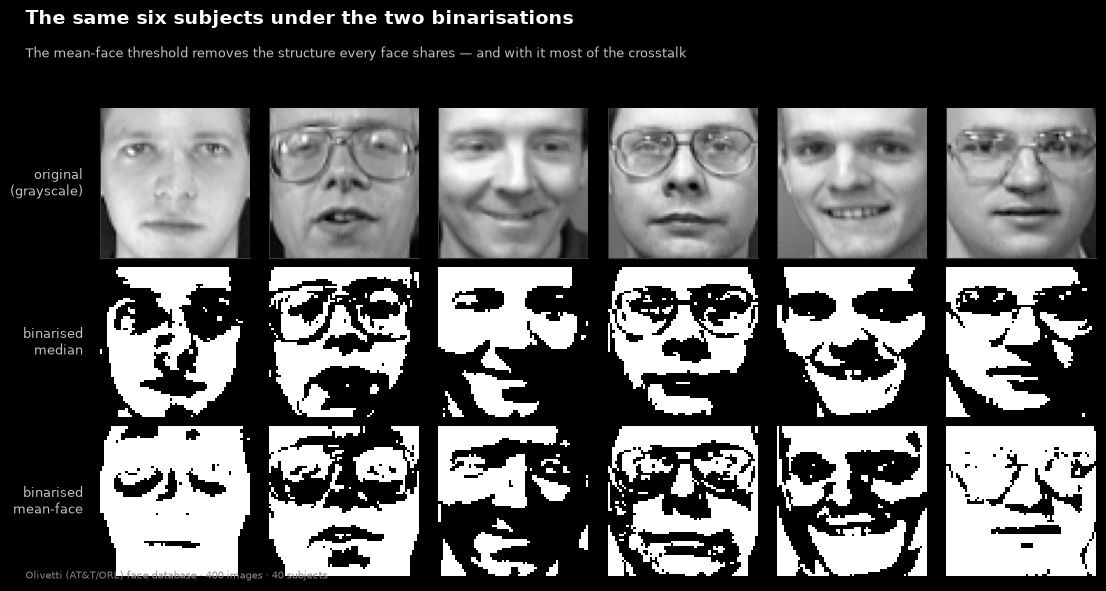

In [9]:
data_median = load_dataset(method="median")
data_meanface = load_dataset(method="mean-face")

print(f"{data_median.n_patterns} images · {data_median.side}×{data_median.side} "
      f"pixels · n = {data_median.n} bits per face")
print(f"{len(np.unique(data_median.target))} subjects, "
      f"{data_median.n_patterns // len(np.unique(data_median.target))} poses each\n")

for name, d in (("median", data_median), ("mean-face", data_meanface)):
    sub = d.X[:, one_index_per_subject(d.target)[:40]]
    print(f"  {BINARIZATION_LABELS[name]:42s} mean |correlation| = "
          f"{mean_correlation(sub):.3f}")

fig, axs = plt.subplots(3, 6, figsize=(11.0, 6.0))
fig.subplots_adjust(left=0.075, right=0.99, top=0.80, bottom=0.02,
                    hspace=0.06, wspace=0.06)
cols = one_index_per_subject(data_median.target)[:6]
for k, col in enumerate(cols):
    axs[0, k].imshow(data_median.gray[col], cmap="gray")
    face_panel(axs[1, k], data_median.X[:, col], data_median.side)
    face_panel(axs[2, k], data_meanface.X[:, col], data_meanface.side)
    for row in range(3):
        axs[row, k].set_xticks([])
        axs[row, k].set_yticks([])
        axs[row, k].grid(False)
for row, label in enumerate(("original\n(grayscale)", "binarised\nmedian",
                             "binarised\nmean-face")):
    axs[row, 0].set_ylabel(label, fontsize=9, color=INK_SECONDARY,
                           rotation=0, ha="right", va="center", labelpad=12)
figure_title(
    fig,
    "The same six subjects under the two binarisations",
    "The mean-face threshold removes the structure every face shares — and with "
    "it most of the crosstalk",
    y=0.965, gap=0.062,
)
credit(fig)
plt.show()

---
# Parte 5 · Codebooks: Hadamard, aleatório, correlacionado

Na BAM de Kosko, a recuperação no sentido **Y→X** é governada pelas
correlações *entre os vetores Y*, e no sentido **X→Y** pelas correlações entre
os vetores X. Como os vetores da camada Y são nossos para escolher — são
rótulos, não dados — eles são **a variável de projeto mais importante do
sistema**. Três famílias:

* `hadamard` — linhas de uma matriz de Hadamard: **exatamente ortogonais**, o
  que anula o termo de *crosstalk* no sentido Y→X;
* `random` — bipolar i.i.d.: ortogonal apenas em média, com desvio
  $O(\sqrt{p})$ — a escolha implícita na literatura clássica;
* `correlated` — família paramétrica com sobreposição média controlada, usada
  para varrer o eixo de "ortogonalidade" no Experimento 4.

In [10]:
CODEBOOK_TYPES = ("hadamard", "random", "correlated")

CODEBOOK_LABELS = {
    "hadamard": "Hadamard (orthogonal)",
    "random": "Random bipolar",
    "correlated": "Correlated",
}


def next_hadamard_order(p_min: int) -> int:
    """Smallest Sylvester-constructible Hadamard order that is >= `p_min`."""
    order = 1
    while order < p_min:
        order *= 2
    return order


def hadamard_codebook(n_patterns: int, p: int | None = None) -> np.ndarray:
    """Orthogonal codebook of `n_patterns` columns with `p` bits each.

    Columns are distinct rows of a Hadamard matrix of order `p` (Sylvester
    construction, `p` a power of two). Two distinct rows of a Hadamard matrix
    have exactly zero inner product, hence `YᵀY = p·I`.

    The first row of a Hadamard matrix is constant (+1, ..., +1); it is dropped
    because it is degenerate as a label.
    """
    if p is None:
        p = next_hadamard_order(n_patterns + 1)
    if p & (p - 1):
        raise ValueError(f"p={p} is not a power of two")
    if n_patterns > p - 1:
        raise ValueError(
            f"a Hadamard matrix of order {p} provides at most {p - 1} "
            f"non-degenerate codes; {n_patterns} were requested"
        )
    H = hadamard(p).astype(np.float64)
    return np.ascontiguousarray(H[1 : n_patterns + 1].T)


def random_codebook(n_patterns: int, p: int, seed: int = 0) -> np.ndarray:
    """I.i.d. bipolar codebook of shape (p, n_patterns)."""
    rng = np.random.default_rng(seed)
    return rng.choice(np.array([-1.0, 1.0]), size=(p, n_patterns))


def correlated_codebook(
    n_patterns: int, p: int, rho: float, seed: int = 0
) -> np.ndarray:
    """Codebook with controlled mean pairwise overlap `rho`.

    Each column is generated by copying a common seed vector and flipping every
    bit with probability `q`. Two codes so generated agree on each bit with
    probability `q² + (1-q)²`, giving an expected overlap
    `E[y_i·y_j]/p = (1-2q)²`. Inverting: `q = (1 - sqrt(rho)) / 2`.
    """
    if not 0.0 <= rho < 1.0:
        raise ValueError("rho must lie in [0, 1)")
    rng = np.random.default_rng(seed)
    q = (1.0 - np.sqrt(rho)) / 2.0
    common = rng.choice(np.array([-1.0, 1.0]), size=(p, 1))
    flip = rng.random((p, n_patterns)) < q
    return np.where(flip, -common, common)


def build_codebook(
    kind: str, n_patterns: int, p: int, *, seed: int = 0, rho: float = 0.3
) -> np.ndarray:
    """Unified dispatch over `CODEBOOK_TYPES`."""
    if kind == "hadamard":
        return hadamard_codebook(n_patterns, p)
    if kind == "random":
        return random_codebook(n_patterns, p, seed)
    if kind == "correlated":
        return correlated_codebook(n_patterns, p, rho, seed)
    raise ValueError(f"unknown codebook: {kind!r}; use {CODEBOOK_TYPES}")


def orthogonality(Y: np.ndarray) -> float:
    """Mean absolute off-diagonal entry of `YᵀY / p`.

    Exactly 0 for a Hadamard codebook and ~1/sqrt(p) for a random one.
    """
    p, k = Y.shape
    if k < 2:
        return 0.0
    G = (Y.T @ Y) / p
    off = ~np.eye(k, dtype=bool)
    return float(np.abs(G[off]).mean())


# The claim above, checked rather than asserted.
for kind in ("hadamard", "random"):
    Yk = build_codebook(kind, 20, 64, seed=SEED)
    print(f"  {CODEBOOK_LABELS[kind]:22s} mean |off-diagonal| of YᵀY/p = "
          f"{orthogonality(Yk):.4f}   (1/√p = {1 / np.sqrt(64):.4f})")

  Hadamard (orthogonal)  mean |off-diagonal| of YᵀY/p = 0.0000   (1/√p = 0.1250)
  Random bipolar         mean |off-diagonal| of YᵀY/p = 0.0980   (1/√p = 0.1250)


---
# Parte 6 · Teoria: a razão sinal-ruído do *crosstalk*

Sondando a rede com um padrão armazenado $x_j$, o campo que chega à unidade
$i$ da camada Y é

$$h_i = n\,y_{j,i} + \sum_{k \neq j} y_{k,i}\,(x_k^{\mathsf T} x_j).$$

Multiplicando por $y_{j,i}$ (que é $\pm 1$), o bit está correto sempre que

$$n + \sum_{k \neq j} y_{j,i}\,y_{k,i}\,c_{kj} > 0, \qquad c_{kj} := x_k^{\mathsf T} x_j.$$

Os produtos $y_{j,i} y_{k,i}$ são $\pm 1$ e, para códigos não patológicos, se
comportam como sinais aleatórios ao longo de $i$. A soma é então uma variável
de média zero e variância $\sum_{k \neq j} c_{kj}^2$, o que define a razão
sinal-ruído

$$\mathrm{SNR}_j = \frac{n}{\sqrt{\sum_{k \neq j} c_{kj}^2}} \quad (\text{X→Y}),
\qquad
\mathrm{SNR}_j = \frac{p}{\sqrt{\sum_{k \neq j} d_{kj}^2}} \quad (\text{Y→X}),$$

com $d_{kj} := y_k^{\mathsf T} y_j$, e — sob a aproximação gaussiana — uma taxa
de erro por bit de $\Phi(-\mathrm{SNR})$.

**Duas consequências que o estudo verifica empiricamente:**

1. Com um codebook de Hadamard, $d_{kj} = 0$ para todo $k \neq j$: o
   *crosstalk* no sentido Y→X **desaparece exatamente**, não apenas em média.
2. No sentido X→Y o *crosstalk* é imposto pelos dados. As faces são fortemente
   correlacionadas entre si, o que colapsa a SNR muito antes do limite
   $\min(n, p)$ conjecturado por Kosko.

In [11]:
def crosstalk_snr(A: np.ndarray, *, per_pattern: bool = True) -> np.ndarray:
    """Hebbian SNR of the patterns in `A` (columns) against their own crosstalk.

    Args:
        A: (dim, P) bipolar matrix of the layer that **probes** the network.
            Pass `X` for the X→Y direction, `Y` for Y→X.
        per_pattern: if `False`, return the mean SNR as a scalar.

    Returns:
        (P,) vector with each pattern's SNR (or a scalar). Patterns perfectly
        orthogonal to all others receive `inf`.
    """
    A = np.asarray(A, dtype=np.float64)
    dim, P = A.shape
    G = A.T @ A  # (P, P); diagonal = dim
    off = G - np.diag(np.diag(G))
    noise = np.sqrt((off**2).sum(axis=0))
    with np.errstate(divide="ignore"):
        snr = np.where(noise > 0, dim / np.where(noise > 0, noise, 1.0), np.inf)
    return snr if per_pattern else float(np.mean(snr[np.isfinite(snr)]))


def predicted_bit_error(snr: np.ndarray) -> np.ndarray:
    """Predicted per-bit error rate, `Φ(-SNR)`."""
    return norm.cdf(-np.asarray(snr, dtype=np.float64))


def predicted_recall_rate(A: np.ndarray, target_dim: int) -> float:
    """Predicted fraction of patterns recalled with **no wrong bit at all**.

    Assumes independence across the `target_dim` bits of the destination layer:
    `P(perfect pattern) = (1 - Φ(-SNR))^target_dim`. The independence
    assumption is optimistic (errors are correlated through the same
    interfering memories), so this curve works as a practical upper bound.
    """
    snr = crosstalk_snr(A)
    pe = predicted_bit_error(snr)
    return float(np.mean((1.0 - pe) ** target_dim))


def predicted_capacity(
    A_full: np.ndarray, target_dim: int, *, threshold: float = 0.95
) -> int:
    """Largest `P` whose predicted recall rate still reaches `threshold`."""
    best = 0
    for P in range(1, A_full.shape[1] + 1):
        if predicted_recall_rate(A_full[:, :P], target_dim) >= threshold:
            best = P
        else:
            break
    return best


def kosko_bound(n: int, p: int) -> int:
    """Kosko's original conjecture (1988): `min(n, p)` storable pairs.

    Included for contrast — the later literature (McEliece et al. 1987 for
    Hopfield; Haines & Hecht-Nielsen 1988 for BAM) showed the real capacity to
    be of order `min(n,p)/(2·log(min(n,p)))` even for random patterns, and this
    study shows it is far smaller still for correlated patterns such as faces.
    """
    return min(n, p)


def asymptotic_bound(n: int, p: int) -> float:
    """Asymptotic capacity `min(n,p) / (2·ln min(n,p))` for i.i.d. patterns."""
    m = min(n, p)
    return m / (2.0 * np.log(m)) if m > 1 else 1.0

---
# Parte 7 · Métricas de recuperação

Todas as funções aceitam matrizes `(dim, B)` com um padrão por coluna e
devolvem um valor por coluna, ou aceitam vetores 1-D e devolvem escalares.

A métrica principal do estudo é `perfect_recall_rate`: a fração de colunas
recuperadas **sem um único bit errado**. É o critério mais estrito, e é o
certo — numa memória endereçável por conteúdo, uma resposta com 3% dos bits
invertidos não está parcialmente certa: é um estado espúrio.

In [12]:
def _as_2d(A: np.ndarray) -> tuple[np.ndarray, bool]:
    A = np.asarray(A, dtype=np.float64)
    if A.ndim == 1:
        return A[:, None], True
    return A, False


def normalized_hamming(A: np.ndarray, B: np.ndarray):
    """Fraction of disagreeing bits between `A` and `B`, per column.

    0 for perfect recall, 0.5 for an uncorrelated answer, and 1 for the exact
    complement (which, in a BAM, is also a fixed point).
    """
    A2, scalar = _as_2d(A)
    B2, _ = _as_2d(B)
    d = (A2 != B2).mean(axis=0)
    return float(d[0]) if scalar else d


def overlap(A: np.ndarray, B: np.ndarray):
    """Overlap `aᵀb/n` per column, in [-1, 1].

    The usual order parameter of associative memories: `m = 1` means exact
    recall, `m ≈ 0` a spurious state unrelated to the target.
    """
    A2, scalar = _as_2d(A)
    B2, _ = _as_2d(B)
    m = (A2 * B2).mean(axis=0)
    return float(m[0]) if scalar else m


def exact_match(A: np.ndarray, B: np.ndarray):
    """Boolean mask of identical columns."""
    A2, scalar = _as_2d(A)
    B2, _ = _as_2d(B)
    ok = (A2 == B2).all(axis=0)
    return bool(ok[0]) if scalar else ok


def perfect_recall_rate(A: np.ndarray, B: np.ndarray) -> float:
    """Fraction of columns recalled with **not a single wrong bit**."""
    A2, _ = _as_2d(A)
    B2, _ = _as_2d(B)
    return float((A2 == B2).all(axis=0).mean())


def bit_accuracy(A: np.ndarray, B: np.ndarray) -> float:
    """Overall fraction of correct bits (a milder metric than the above)."""
    A2, _ = _as_2d(A)
    B2, _ = _as_2d(B)
    return float((A2 == B2).mean())


def confidence_interval(samples: np.ndarray, *,
                        level: float = 0.95) -> tuple[float, float]:
    """Mean and half-width of the normal CI for the mean of `samples`."""
    a = np.asarray(samples, dtype=np.float64).ravel()
    if a.size < 2:
        return float(a.mean()), 0.0
    z = float(norm.ppf(0.5 + level / 2.0))
    return float(a.mean()), float(z * a.std(ddof=1) / np.sqrt(a.size))


def bit_flip_noise(X: np.ndarray, prob: float,
                   rng: np.random.Generator) -> np.ndarray:
    """Flip each bit of `X` independently with probability `prob`."""
    if not 0.0 <= prob <= 1.0:
        raise ValueError("prob must lie in [0, 1]")
    mask = rng.random(X.shape) < prob
    return np.where(mask, -X, X)


def occlude(
    X: np.ndarray, fraction: float, side: int, *,
    rng: np.random.Generator | None = None
) -> np.ndarray:
    """Zero out (occlude) the bottom `fraction` of rows of each column's image.

    Unlike bit noise, occlusion supplies no wrong information: hidden pixels
    enter with zero local field. This is the "recall from partial evidence"
    scenario, and the BAM does visibly better at it.
    """
    del rng  # occlusion is deterministic; signature matches bit_flip_noise
    if not 0.0 <= fraction <= 1.0:
        raise ValueError("fraction must lie in [0, 1]")
    Xo = np.array(X, dtype=np.float64)
    n_rows = int(round(fraction * side))
    if n_rows:
        Xo.reshape(side, side, -1)[side - n_rows :, :, :] = 0.0
    return Xo

---
# Parte 8 · O modelo BAM e as quatro regras

## Formalização

Uma BAM armazena `P` pares de padrões bipolares $(x_k, y_k)$, com
$x_k \in \{-1,+1\}^n$ na camada X e $y_k \in \{-1,+1\}^p$ na camada Y. A
recuperação é uma **ressonância** entre as camadas:

$$y(t+1) = \operatorname{sgn}(W^{\mathsf T} x(t)) \quad (\text{X→Y}), \qquad
x(t+1) = \operatorname{sgn}(W\, y(t+1)) \quad (\text{Y→X}).$$

Kosko (1988) mostrou que, para **qualquer** $W$, a função de Lyapunov

$$E(x, y) = -x^{\mathsf T} W y$$

é não-crescente sob essas atualizações, de modo que a rede sempre converge
para um par estável — a BAM é *incondicionalmente estável para qualquer matriz
de pesos*. A questão científica, portanto, nunca é **se** ela converge: é
**para onde** ela converge, isto é, se os pares armazenados são de fato pontos
fixos e quão grandes são suas bacias de atração.

## O termo de *crosstalk*

Sob a regra de Hebb $W = \sum_k x_k y_k^{\mathsf T}$, sondar com o padrão
armazenado $x_j$ dá

$$W^{\mathsf T} x_j = n\,y_j + \underbrace{\sum_{k \neq j} y_k\,(x_k^{\mathsf T} x_j)}_{\text{crosstalk}}$$

e, simetricamente, o *crosstalk* no sentido inverso é
$\sum_{k \neq j} x_k (y_k^{\mathsf T} y_j)$. Note a **assimetria decisiva**: a
recuperação **X→Y** é degradada pela correlação entre as *faces*, que não
podemos escolher; a recuperação **Y→X** é degradada pela correlação entre os
*códigos*, que podemos. Este projeto explora exatamente essa assimetria.

## As quatro regras implementadas

| Regra | Forma | Referência |
|---|---|---|
| `hebb` | $W = \sum_k x_k y_k^{\mathsf T}$ | Kosko (1988) — a linha de base histórica |
| `multiple_training` | $W = \sum_k q_k x_k y_k^{\mathsf T}$, com $q_k$ ajustados iterativamente | Wang, Cruz & Mulligan (1990) |
| `least_squares` | minimiza o erro bidirecional ponderado por $\lambda$; equação de Sylvester resolvida em forma fechada via SVD | derivada neste trabalho |
| `dense` | interação exponencial, sem matriz de pesos | Krotov & Hopfield (2016); Ramsauer et al. (2020) |

In [13]:
RULES = ("hebb", "multiple_training", "least_squares", "dense")

RULE_LABELS = {
    "hebb": "Hebb (Kosko, 1988)",
    "multiple_training": "Multiple training",
    "least_squares": "Least squares",
    "dense": "Dense (exponential)",
}

# Update directions, used as trajectory step labels.
X_TO_Y = "X->Y"
Y_TO_X = "Y->X"


def sign(local_field: np.ndarray, previous: np.ndarray) -> np.ndarray:
    """Sign with ties broken by the previous state.

    The standard convention in the BAM literature is to leave a unit unchanged
    when its local field is exactly zero — this is what preserves the
    monotonicity of the energy.
    """
    return np.where(local_field > 0.0, 1.0,
                    np.where(local_field < 0.0, -1.0, previous))


def _validate_bipolar(M: np.ndarray, name: str) -> np.ndarray:
    M = np.asarray(M, dtype=np.float64)
    if M.ndim != 2:
        raise ValueError(f"{name} must be 2-D (patterns in columns), got {M.ndim}-D")
    if not np.all(np.isin(M, (-1.0, 1.0))):
        raise ValueError(f"{name} must contain only -1 and +1")
    return np.ascontiguousarray(M)

### As três regras lineares

A regra `dense` não produz matriz de pesos e é implementada dentro da classe
`BAM`, adiante.

**Nota de implementação em `_multiple_training_rule`:** o laço nunca
materializa `W`. Como $W = X\,\mathrm{diag}(q)\,Y^{\mathsf T}$, os campos sobre
os padrões armazenados são $W^{\mathsf T}X = Y\,\mathrm{diag}(q)\,(X^{\mathsf T}X)$
e $WY = X\,\mathrm{diag}(q)\,(Y^{\mathsf T}Y)$, bastando pré-computar as duas
matrizes de Gram $P\times P$ uma única vez. Isso troca um produto
$O(npP)$ por época por um $O(nP^2)$ — com $n = 4096$ e $p = 256$ é a diferença
entre a varredura de capacidade levar minutos ou horas.

In [14]:
def _hebb_rule(X: np.ndarray, Y: np.ndarray) -> np.ndarray:
    """`W = Σ_k x_k y_kᵀ = X Yᵀ` (Hebbian correlation, Kosko 1988)."""
    return X @ Y.T


def _multiple_training_rule(
    X: np.ndarray, Y: np.ndarray, *, max_epochs: int = 200
) -> tuple[np.ndarray, np.ndarray, bool]:
    """Multiple-training learning (Wang, Cruz & Mulligan, 1990).

    Keeps the Hebbian form but presents each pair an integer number `q_k` of
    times. At every epoch, pairs that are not yet fixed points have their
    multiplicity incremented. If the algorithm terminates with all pairs
    stable, the training set is guaranteed to be stored.

    With strongly correlated patterns the procedure may fail to converge within
    the epoch budget — a situation we record explicitly rather than silence,
    because it is exactly what happens with real faces.

    Returns:
        `(W, q, converged)` — the weight matrix, the multiplicities, and
        whether every pair became stable within the epoch budget.
    """
    Gx = X.T @ X
    Gy = Y.T @ Y
    q = np.ones(X.shape[1], dtype=np.float64)

    def unstable(q: np.ndarray) -> np.ndarray:
        forward = sign(Y @ (q[:, None] * Gx), Y) == Y  # (p, P)
        backward = sign(X @ (q[:, None] * Gy), X) == X  # (n, P)
        return ~(forward.all(axis=0) & backward.all(axis=0))

    converged = False
    for _ in range(max_epochs):
        bad = unstable(q)
        if not bad.any():
            converged = True
            break
        q[bad] += 1.0
    else:
        converged = not unstable(q).any()

    W = X @ (q[:, None] * Y.T)
    return W, q, converged


def _least_squares_rule(
    X: np.ndarray, Y: np.ndarray, *, lam: float = 0.5, tol: float = 1e-10
) -> np.ndarray:
    """Minimise the bidirectional reconstruction error weighted by `lam`.

    The patterns are first normalised to unit norm, `X̃ = X/√n` and `Ỹ = Y/√p`,
    and the objective is

        J(W̃) = λ·‖W̃ᵀX̃ − Ỹ‖²_F + (1−λ)·‖W̃Ỹ − X̃‖²_F,   λ ∈ [0, 1].

    The normalisation is essential and not cosmetic: without it the singular
    values of `X` (of order √(nP) ≈ 286 for faces) are tens of times larger
    than those of `Y` (√(pP) ≈ 36), `λ` stops being interpretable, and the X→Y
    direction dominates the fit for any `λ > 0`. After normalising, `λ = 0.5`
    genuinely balances the two directions, `λ → 1` recovers the classical
    pseudo-inverse (exact X→Y) and `λ → 0` recovers — for a Hadamard codebook —
    the Hebb rule itself up to scale.

    Setting the gradient to zero yields the Sylvester equation

        λ·X̃X̃ᵀW̃ + (1−λ)·W̃ỸỸᵀ = X̃Ỹᵀ.

    With the SVDs `X̃ = U_x S̃_x V_xᵀ` and `Ỹ = U_y S̃_y V_yᵀ`, the minimum-norm
    solution has the form `W̃ = U_x A U_yᵀ`, the equation **diagonalises**, and
    every entry of `A` follows in closed form:

        A_ij = σ̃_i C_ij τ̃_j / (λ σ̃_i² + (1−λ) τ̃_j²),   C = V_xᵀ V_y.

    The cost is that of two thin SVDs — O(nP²) — rather than solving a dense
    n×n Sylvester equation, which is what makes the rule tractable at n = 4096.
    The global scale of `W` is irrelevant, since recall only uses the sign of
    the field.

    Sanity check: if `XᵀX = n·I` and `YᵀY = p·I` (orthogonal patterns on both
    sides), then σ̃ = τ̃ = 1 and `C = I`, hence `A = I` and `W ∝ X Yᵀ` — the
    Hebb rule, as it should be, since without correlation Hebb is already
    optimal.
    """
    if not 0.0 <= lam <= 1.0:
        raise ValueError("lam must lie in [0, 1]")
    n, p = X.shape[0], Y.shape[0]

    Ux, Sx, Vxt = np.linalg.svd(X, full_matrices=False)
    Uy, Sy, Vyt = np.linalg.svd(Y, full_matrices=False)
    Sx = Sx / np.sqrt(n)  # singular values of X̃
    Sy = Sy / np.sqrt(p)  # singular values of Ỹ

    rx = int((Sx > tol * Sx.max()).sum())
    ry = int((Sy > tol * Sy.max()).sum())
    Ux, Sx, Vxt = Ux[:, :rx], Sx[:rx], Vxt[:rx]
    Uy, Sy, Vyt = Uy[:, :ry], Sy[:ry], Vyt[:ry]

    C = Vxt @ Vyt.T  # (rx, ry)
    denom = lam * Sx[:, None] ** 2 + (1.0 - lam) * Sy[None, :] ** 2
    A = Sx[:, None] * C * Sy[None, :] / np.maximum(denom, tol)
    return Ux @ A @ Uy.T

In [15]:
@dataclass
class Trajectory:
    """Full history of one recall, for analysis and animation."""

    xs: list = field(default_factory=list)
    ys: list = field(default_factory=list)
    energies: list = field(default_factory=list)
    steps: list = field(default_factory=list)
    converged: bool = False
    n_iter: int = 0

    @property
    def x_final(self) -> np.ndarray:
        return self.xs[-1]

    @property
    def y_final(self) -> np.ndarray:
        return self.ys[-1]

    @property
    def n_frames(self) -> int:
        return len(self.xs)

    def energy_is_monotone(self, *, tol: float = 1e-9) -> bool:
        """Empirical check of Kosko's stability theorem."""
        e = np.asarray(self.energies)
        return bool(np.all(np.diff(e) <= tol))

### A classe `BAM`

Um detalhe central deste estudo aparece na distinção entre dois modos de uso:

* `associate_forward` / `associate_backward` — **uma única passagem**, sem
  realimentação. Mede a qualidade do mapa $x \mapsto \operatorname{sgn}(W^{\mathsf T}x)$
  isoladamente.
* `recall` / `recall_batch` — **ressonância completa**, deixando a rede
  iterar até um ponto fixo.

A distinção é essencial aqui porque as duas direções da BAM têm qualidades
muito diferentes, e **a ressonância propaga o erro da direção ruim para a
boa**. É o resultado central do Experimento 2.

In [16]:
class BAM:
    """Bidirectional Associative Memory with a selectable learning rule.

    Args:
        rule: one of `RULES`.
        max_iter: maximum number of full resonance iterations.
        beta: inverse temperature of the ``dense`` rule. Larger values make
            recall more selective (less mixing between nearby memories).
        lam: direction weight of the ``least_squares`` rule.
        max_mt_epochs: epoch budget of the ``multiple_training`` rule.

    Example:
        >>> rng = np.random.default_rng(0)
        >>> X = rng.choice([-1.0, 1.0], size=(64, 4))
        >>> Y = rng.choice([-1.0, 1.0], size=(16, 4))
        >>> model = BAM("hebb").fit(X, Y)
        >>> traj = model.recall(x0=X[:, 0])
        >>> bool(np.array_equal(traj.y_final, Y[:, 0]))
        True
    """

    def __init__(
        self,
        rule: str = "hebb",
        *,
        max_iter: int = 30,
        beta: float = 12.0,
        lam: float = 0.5,
        max_mt_epochs: int = 200,
    ) -> None:
        if rule not in RULES:
            raise ValueError(f"unknown rule: {rule!r}; use {RULES}")
        self.rule = rule
        self.max_iter = max_iter
        self.beta = beta
        self.lam = lam
        self.max_mt_epochs = max_mt_epochs

        self.W = None
        self.X_ = None
        self.Y_ = None
        self.q_ = None
        self.mt_converged_ = None

    # -- construction -------------------------------------------------------
    def fit(self, X: np.ndarray, Y: np.ndarray) -> "BAM":
        """Store the pairs `(column_k(X), column_k(Y))`."""
        X = _validate_bipolar(X, "X")
        Y = _validate_bipolar(Y, "Y")
        if X.shape[1] != Y.shape[1]:
            raise ValueError(
                f"X has {X.shape[1]} patterns and Y has {Y.shape[1]}; they must match"
            )
        self.X_, self.Y_ = X, Y

        if self.rule == "hebb":
            self.W = _hebb_rule(X, Y)
        elif self.rule == "multiple_training":
            self.W, self.q_, self.mt_converged_ = _multiple_training_rule(
                X, Y, max_epochs=self.max_mt_epochs
            )
        elif self.rule == "least_squares":
            self.W = _least_squares_rule(X, Y, lam=self.lam)
        else:  # dense — the interaction does not factor into a weight matrix
            self.W = None
        return self

    @property
    def n(self) -> int:
        return self.X_.shape[0]

    @property
    def p(self) -> int:
        return self.Y_.shape[0]

    @property
    def n_patterns(self) -> int:
        return self.X_.shape[1]

    @property
    def linear(self) -> bool:
        """`True` for the rules that reduce to a weight matrix."""
        return self.rule != "dense"

    # -- dynamics -----------------------------------------------------------
    def _dense_weights(self, X: np.ndarray, Y: np.ndarray) -> np.ndarray:
        """Per-probe `softmax(β·s_k)` attention weights of the dense rule.

        The similarity `s_k` adds the normalised overlaps in both layers, which
        is exactly the modern Hopfield energy applied to the concatenated
        vector `z = [x; y]`.
        """
        s = (self.X_.T @ X) / self.n + (self.Y_.T @ Y) / self.p  # (P, B)
        return softmax(self.beta * s, axis=0)

    def field_y(self, X: np.ndarray, Y: np.ndarray) -> np.ndarray:
        """Local field received by layer Y (pre-activation), batched."""
        if self.linear:
            return self.W.T @ X
        return self.Y_ @ self._dense_weights(X, Y)

    def field_x(self, X: np.ndarray, Y: np.ndarray) -> np.ndarray:
        """Local field received by layer X (pre-activation), batched."""
        if self.linear:
            return self.W @ Y
        return self.X_ @ self._dense_weights(X, Y)

    def energy(self, X: np.ndarray, Y: np.ndarray) -> np.ndarray:
        """Lyapunov energy of each state pair (batched).

        Linear rules: `E = -xᵀWy` (Kosko, 1988).
        Dense rule: `E = -(1/β)·log Σ_k exp(β s_k)`, the log-sum-exp energy of
        dense associative memories.
        """
        X = np.atleast_2d(X.T).T if X.ndim == 1 else X
        Y = np.atleast_2d(Y.T).T if Y.ndim == 1 else Y
        if self.linear:
            return -np.einsum("ib,ij,jb->b", X, self.W, Y)
        s = (self.X_.T @ X) / self.n + (self.Y_.T @ Y) / self.p
        return -logsumexp(self.beta * s, axis=0) / self.beta

    # -- single-pass association -------------------------------------------
    def associate_forward(self, X0: np.ndarray, Y0=None) -> np.ndarray:
        """A single X→Y propagation, with no feedback.

        This is "pure" heteroassociation: it measures the quality of the map
        `x ↦ sgn(Wᵀx)` in isolation. It contrasts with `recall_batch`, which
        lets the network resonate. The distinction is essential in this study
        because the two BAM directions have very different quality, and
        resonance propagates the error of the bad direction into the good one.
        """
        X0 = np.atleast_2d(np.asarray(X0, dtype=np.float64).T).T if X0.ndim == 1 else X0
        Y0 = np.zeros((self.p, X0.shape[1])) if Y0 is None else Y0
        return sign(self.field_y(X0, Y0), Y0)

    def associate_backward(self, Y0: np.ndarray, X0=None) -> np.ndarray:
        """A single Y→X propagation, with no feedback."""
        Y0 = np.atleast_2d(np.asarray(Y0, dtype=np.float64).T).T if Y0.ndim == 1 else Y0
        X0 = np.zeros((self.n, Y0.shape[1])) if X0 is None else X0
        return sign(self.field_x(X0, Y0), X0)

    # -- recall by resonance ------------------------------------------------
    def recall(self, *, x0=None, y0=None, max_iter=None,
               record: bool = True) -> Trajectory:
        """Recall a single pair from a probe, keeping the whole trajectory.

        Args:
            x0: probe in layer X. If `None`, recall starts from Y.
            y0: probe in layer Y. If `None`, it is initialised to zeros, which
                makes the first half-iteration driven by `x0` alone.
            max_iter: overrides `self.max_iter`.
            record: if `False`, only the final state is kept (faster).

        Returns:
            The `Trajectory` traversed. Each frame is **half** an iteration
            (one layer update), which is the granularity at which the energy is
            guaranteed to be non-increasing.
        """
        if x0 is None and y0 is None:
            raise ValueError("provide at least one of the probes x0 or y0")
        max_iter = self.max_iter if max_iter is None else max_iter

        x = np.zeros(self.n) if x0 is None else np.asarray(x0, dtype=np.float64).copy()
        y = np.zeros(self.p) if y0 is None else np.asarray(y0, dtype=np.float64).copy()
        # Which half-iteration comes first depends on the probed layer.
        starts_at_x = x0 is not None

        traj = Trajectory()

        def note(step: str) -> None:
            if record or step == "final":
                traj.xs.append(x.copy())
                traj.ys.append(y.copy())
                traj.energies.append(float(self.energy(x[:, None], y[:, None])[0]))
                traj.steps.append(step)

        note("probe")
        for it in range(max_iter):
            x_prev, y_prev = x.copy(), y.copy()
            if starts_at_x:
                y = sign(self.field_y(x[:, None], y[:, None])[:, 0], y)
                note(X_TO_Y)
                x = sign(self.field_x(x[:, None], y[:, None])[:, 0], x)
                note(Y_TO_X)
            else:
                x = sign(self.field_x(x[:, None], y[:, None])[:, 0], x)
                note(Y_TO_X)
                y = sign(self.field_y(x[:, None], y[:, None])[:, 0], y)
                note(X_TO_Y)
            traj.n_iter = it + 1
            if np.array_equal(x, x_prev) and np.array_equal(y, y_prev):
                traj.converged = True
                break
        return traj

    def recall_batch(self, *, X0=None, Y0=None, max_iter=None):
        """Vectorised version of `recall` for statistical sweeps.

        Returns:
            `(X, Y, iterations, converged)` — final states of both layers, the
            number of iterations each probe took, and a convergence mask.
        """
        if X0 is None and Y0 is None:
            raise ValueError("provide at least one of the probes X0 or Y0")
        max_iter = self.max_iter if max_iter is None else max_iter
        b = X0.shape[1] if X0 is not None else Y0.shape[1]

        X = np.zeros((self.n, b)) if X0 is None else np.array(X0, dtype=np.float64)
        Y = np.zeros((self.p, b)) if Y0 is None else np.array(Y0, dtype=np.float64)
        starts_at_x = X0 is not None

        iterations = np.full(b, max_iter, dtype=np.int64)
        converged = np.zeros(b, dtype=bool)

        for it in range(max_iter):
            X_prev, Y_prev = X.copy(), Y.copy()
            if starts_at_x:
                Y = sign(self.field_y(X, Y), Y)
                X = sign(self.field_x(X, Y), X)
            else:
                X = sign(self.field_x(X, Y), X)
                Y = sign(self.field_y(X, Y), Y)
            stable = (X_prev == X).all(axis=0) & (Y_prev == Y).all(axis=0)
            newly = stable & ~converged
            iterations[newly] = it + 1
            converged |= stable
            if converged.all():
                break
        return X, Y, iterations, converged

    # -- diagnostics --------------------------------------------------------
    def stable_pairs(self) -> np.ndarray:
        """Mask of stored pairs that are fixed points of the network."""
        Xf, Yf, _, _ = self.recall_batch(X0=self.X_, Y0=self.Y_, max_iter=1)
        return (Xf == self.X_).all(axis=0) & (Yf == self.Y_).all(axis=0)

    def __repr__(self) -> str:
        if self.X_ is None:
            return f"BAM(rule={self.rule!r}, not fitted)"
        return (
            f"BAM(rule={self.rule!r}, n={self.n}, p={self.p}, "
            f"P={self.n_patterns})"
        )


def recall(model: BAM, x0=None, y0=None, **kw) -> Trajectory:
    """Functional shortcut for `model.recall`."""
    return model.recall(x0=x0, y0=y0, **kw)

### A memória em funcionamento, em quatro linhas

Antes de qualquer varredura, uma verificação mínima: armazenar 20 faces com
códigos de Hadamard, apresentar uma face armazenada e checar que o código
volta. É o "olá, mundo" da BAM.

In [17]:
_data = data_meanface
_X = _data.X[:, one_index_per_subject(_data.target)[:20]]
_Y = build_codebook("hadamard", 20, 64)

_model = BAM("dense").fit(_X, _Y)
print(_model)
print("  stored pairs that are fixed points:",
      f"{_model.stable_pairs().mean():.0%}")

_traj = _model.recall(x0=_X[:, 0])
print(f"  recall from a stored face: converged in {_traj.n_iter} iterations, "
      f"energy monotone = {_traj.energy_is_monotone()}")
print(f"  the code came back exactly: {np.array_equal(_traj.y_final, _Y[:, 0])}")
print(f"  the face came back exactly: {np.array_equal(_traj.x_final, _X[:, 0])}")

del _data, _X, _Y, _model, _traj

BAM(rule='dense', n=4096, p=64, P=20)
  stored pairs that are fixed points: 100%
  recall from a stored face: converged in 2 iterations, energy monotone = True
  the code came back exactly: True
  the face came back exactly: True


---
# Parte 9 · Montagem das animações

Quatro animações são produzidas, uma por pergunta que o estudo responde. Cada
uma segue as mesmas regras:

* **Uma mensagem por animação.** O título enuncia uma pergunta, os painéis a
  respondem, e os últimos quadros soletram a conclusão em palavras — o
  espectador nunca deve ter de inferir o desfecho a partir dos eixos.
* **Um referencial fixo.** Os limites dos eixos são definidos antes do
  primeiro quadro, então o que se move na tela são os dados, nunca a escala.
  O espaço para a legenda de fechamento é reservado desde o início, para que
  nada se desloque quando ela aparece.
* **Poucas marcas, grandes.** Duas faces de exemplo em vez de seis pequenas;
  linhas grossas; tipografia não menor que ~2% da largura do quadro.
* **A identidade nunca só pela cor.** Cada série carrega também um marcador e
  um rótulo direto na ponta, além da cor.
* **Tela quadrada 1080×1080**, porque estas são lidas em telas de celular,
  onde uma figura larga encolhe até seus rótulos sumirem.

In [18]:
# Type scale used by every animation, in points at 100 dpi.
FONT_SCALE = 1.8
TITLE_SIZE = 30.0
SUBTITLE_SIZE = 15.5
PANEL_TITLE_SIZE = 15.0
PANEL_SUBTITLE_SIZE = 13.0
BODY_SIZE = 14.5
TAKEAWAY_SIZE = 15.0
CREDIT_SIZE = 11.0

# Vertical band reserved at the bottom for the closing caption. Reserved from
# the first frame so that its appearance never reflows the panels above; the
# margin also has to clear the bottom axis label.
TAKEAWAY_Y = 0.046
PANEL_BOTTOM = 0.170

# Vertical room reserved above the panels for the sweep badge ("P = 200 pairs",
# "80% corrupted"). It gets its own line so it can never land on a panel title.
BADGE_GAP = 0.042

_SUPERSCRIPTS = str.maketrans("0123456789", "⁰¹²³⁴⁵⁶⁷⁸⁹")


def _superscript(n: int) -> str:
    """Render an integer with superscript digits (for scale labels)."""
    return str(n).translate(_SUPERSCRIPTS)


def new_square_figure(name: str, **fmt) -> tuple:
    """Create the square canvas with its Portuguese title block already set.

    Returns:
        `(fig, top)` — the figure and the y coordinate below which the panels
        may start.
    """
    apply_theme(scale=FONT_SCALE)
    title, subtitle = TITLES[name]
    fig = plt.figure(figsize=GIF_FIGSIZE)
    # A 30 pt line occupies ~0.047 of a 1080 px canvas, a 15.5 pt line ~0.025.
    # The title block is measured rather than guessed so that two-line titles
    # never run into the subtitle.
    title_lines = title.count("\n") + 1
    subtitle_lines = subtitle.count("\n") + 1
    title_block = 0.047 * title_lines + 0.012
    figure_title(
        fig, title, subtitle.format(**fmt),
        title_size=TITLE_SIZE, subtitle_size=SUBTITLE_SIZE,
        y=0.985, gap=title_block,
    )
    credit(fig, PT_CREDIT, fontsize=CREDIT_SIZE, y=0.010)
    top = 0.985 - title_block - 0.026 * subtitle_lines - 0.030
    return fig, top


def takeaway(fig, name: str, *, color: str | None = None, width: int = 66) -> list:
    """Draw the animation's closing caption in the reserved bottom band.

    The text is wrapped here rather than in the string table so that the
    strings stay editable prose instead of pre-broken lines.
    """
    text = textwrap.fill(TAKEAWAYS[name], width=width)
    color = SERIES[2] if color is None else color
    bar = fig.text(0.012, TAKEAWAY_Y, "▍", ha="left", va="bottom",
                   fontsize=TAKEAWAY_SIZE + 8, color=color)
    body = fig.text(0.042, TAKEAWAY_Y, text, ha="left", va="bottom",
                    fontsize=TAKEAWAY_SIZE, color=INK_PRIMARY,
                    linespacing=1.45)
    return [bar, body]


def badge(fig, y: float, text: str):
    """The sweep counter, on its own line above the panels."""
    return fig.text(0.012, y, text, fontsize=18, fontweight="bold",
                    color=INK_PRIMARY, ha="left", va="bottom")


def save_gif(
    fig,
    update: Callable[[int], None],
    n_frames: int,
    name: str,
    *,
    fps: int = FPS,
    hold_last: int = 16,
    hold_first: int = 4,
    out_dir=None,
) -> Path:
    """Render `n_frames` calls of `update` into a looping GIF.

    Args:
        update: function that draws frame `i` (0-indexed).
        hold_first: extra frames repeating the first state.
        hold_last: extra frames repeating the last state, so the closing
            caption stays on screen long enough to be read.

    Returns:
        Path of the written file. (Pillow merges consecutive identical frames
        into a single longer-duration frame, so the holds cost no file size.)
    """
    out_dir = GIFS_DIR if out_dir is None else Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    target = out_dir / f"{name}.gif"

    order = [0] * hold_first + list(range(n_frames)) + [n_frames - 1] * hold_last

    anim = FuncAnimation(
        fig, lambda k: update(order[k]), frames=len(order),
        interval=1000 / fps, blit=False, repeat=True,
    )
    anim.save(target, writer=PillowWriter(fps=fps),
              savefig_kwargs={"facecolor": PAGE})
    plt.close(fig)
    return target


def series_line(ax, x, y, *, color: str, marker: str, order: int = 0,
                zorder_base: int = 3):
    """One data series drawn at the animation's mark weights.

    Line widths decrease with `order` so that coincident series — frequent in
    this study, where several conditions saturate together at 0 % or 100 % —
    remain visible as rings around one another instead of vanishing.
    """
    (line,) = ax.plot(x, y, color=color, lw=7.0 - 1.6 * order, marker=marker,
                      ms=13.0 - 1.6 * order, markeredgecolor=SURFACE,
                      markeredgewidth=1.6, zorder=zorder_base + order)
    return line


def noise_preroll(
    x_clean: np.ndarray, final_prob: float, seed: int, *, n_frames: int = 7
) -> list:
    """Intro frames showing the face being progressively corrupted.

    Without this intro the viewer sees the noisy probe already made and has no
    way to judge how much information was destroyed before recall. The frames
    use **cumulative** noise (the same mask keeps growing), so the last frame is
    exactly the probe used for recall.
    """
    rng = np.random.default_rng(seed)
    draw = rng.random(x_clean.shape)
    frames = []
    for k in range(n_frames):
        prob = final_prob * (k / (n_frames - 1)) if n_frames > 1 else final_prob
        x = np.where(draw < prob, -x_clean, x_clean)
        caption = STAGE_CLEAN if k == 0 else corrupting(prob * 100)
        frames.append((x, caption))
    return frames


def label_ends(ax, ends, **kw) -> list:
    """End-of-line labels at a shared x, stacked so they never collide."""
    if not ends:
        return []
    x_label = max(e[0] for e in ends)
    return label_line_ends(
        ax, [(x_label, y, text) for _, y, text in ends],
        fontsize=kw.pop("fontsize", BODY_SIZE - 2.0),
        separation=kw.pop("separation", 0.115), **kw,
    )

In [19]:
@dataclass
class _Frame:
    """One rendered instant of the bidirectional-recall animation."""

    x: np.ndarray
    y: np.ndarray
    stage: str
    phase: int  # 0 = building the probe, 1 = X→Y→X, 2 = Y→X only
    t: float | None = None  # position on the energy axis
    energy: float | None = None


def _stage_name(step: str, is_last: bool) -> str:
    """Human-readable caption for one half-iteration."""
    if is_last:
        return STAGE_STABLE
    return {
        "probe": STAGE_PROBE_SHOWN,
        "X->Y": STAGE_FORWARD,
        "Y->X": STAGE_BACKWARD,
    }.get(step, step)


def bidirectional_recall_gif(
    model: BAM,
    *,
    probe: np.ndarray,
    x_target: np.ndarray,
    y_target: np.ndarray,
    side: int,
    name: str,
    preroll: list,
    fps: int = 4,
) -> Path:
    """The defining capability of a BAM, in two acts.

    Act 1 feeds a corrupted face and lets the network resonate until it
    returns both the face and its code. Act 2 then erases the face entirely and
    hands the network nothing but the code — from which the same face
    reappears. One weight matrix, two directions.

    The energy panel carries the theoretical argument: it descends in both
    acts, and jumps only where *we* reset the state, never where the network
    updates it.
    """
    traj_fwd = model.recall(x0=probe)
    traj_bwd = model.recall(y0=y_target)

    e_fwd = np.asarray(traj_fwd.energies)
    e_bwd = np.asarray(traj_bwd.energies)
    n_fwd = len(e_fwd)

    frames = [
        _Frame(x=x, y=np.zeros_like(y_target), stage=caption, phase=0)
        for x, caption in preroll
    ]
    for i in range(n_fwd):
        frames.append(_Frame(
            x=traj_fwd.xs[i], y=traj_fwd.ys[i], t=float(i), energy=float(e_fwd[i]),
            stage=_stage_name(traj_fwd.steps[i], i == n_fwd - 1), phase=1,
        ))
    for i in range(len(e_bwd)):
        frames.append(_Frame(
            x=traj_bwd.xs[i], y=traj_bwd.ys[i], t=float(n_fwd + i),
            energy=float(e_bwd[i]), phase=2,
            stage=(STAGE_ERASE if i == 0
                   else _stage_name(traj_bwd.steps[i], i == len(e_bwd) - 1)),
        ))

    fig, top = new_square_figure(name)
    gs = fig.add_gridspec(
        4, 2, height_ratios=[1.0, 0.13, 0.34, 0.86],
        left=0.115, right=0.965, top=top, bottom=PANEL_BOTTOM,
        hspace=0.26, wspace=0.10,
    )
    ax_x = fig.add_subplot(gs[0, 0])
    ax_err = fig.add_subplot(gs[0, 1])
    ax_code = fig.add_subplot(gs[1, :])
    ax_txt = fig.add_subplot(gs[2, :])
    ax_txt.axis("off")
    ax_e = fig.add_subplot(gs[3, :])

    all_energy = np.concatenate([e_fwd, e_bwd])
    e_min, e_max = float(all_energy.min()), float(all_energy.max())
    span = e_max - e_min
    margin = 0.12 * (span + 1e-12)
    # Energies span ~1 (dense rule) to ~1e8 (multiple training); large
    # magnitudes are rescaled by a power of ten spelled out in the axis label.
    exponent = 0
    while span / 10**exponent >= 1e4:
        exponent += 3
    scale = 10.0**exponent
    span_scaled = span / scale
    decimals = 0 if span_scaled >= 10 else (2 if span_scaled >= 0.1 else 4)
    suffix = f"  (× 10{_superscript(exponent)})" if exponent else ""

    total = n_fwd + len(e_bwd)
    ax_e.set_xlim(-0.5, total - 0.5)
    ax_e.set_ylim((e_min - margin) / scale, (e_max + margin) / scale)
    ax_e.set_xlabel(AXIS_HALF_ITER)
    ax_e.set_ylabel(f"{AXIS_ENERGY}{suffix}")
    ax_e.set_title(PANEL_ENERGY, fontsize=PANEL_TITLE_SIZE + 2,
                   color=INK_PRIMARY, pad=8)
    ax_e.yaxis.set_major_formatter(num_fmt(decimals, ptbr=True))
    # The divider marks where we reset the state; the network itself never
    # raises the energy, and the two descents make that visible.
    ax_e.axvline(n_fwd - 0.5, color=INK_MUTED, lw=1.4, ls=(0, (4, 4)), zorder=1)

    movable: list = []

    def update(k: int) -> None:
        nonlocal movable
        for a in movable:
            a.remove()
        movable = []
        ax_x.clear()
        ax_err.clear()
        ax_code.clear()

        f = frames[k]
        face_panel(ax_x, f.x, side, PANEL_X_STATE, title_size=PANEL_TITLE_SIZE)
        wrong_x = error_panel(ax_err, f.x, x_target, side, PANEL_X_ERROR,
                              title_size=PANEL_TITLE_SIZE)
        code_panel(ax_code, f.y, PANEL_Y_STATE, target=y_target,
                   title_size=PANEL_TITLE_SIZE, marker_size=24)

        if f.phase:
            seg = [g for g in frames if g.phase == f.phase and g.t <= f.t]
            movable.append(ax_e.plot(
                [g.t for g in seg], [g.energy / scale for g in seg],
                color=SERIES[0], lw=3.6, zorder=3)[0])
            movable.append(ax_e.plot(
                [f.t], [f.energy / scale], marker="o", ms=13,
                color=SERIES[0], markeredgecolor=SURFACE,
                markeredgewidth=2.6, zorder=5)[0])
            if f.phase == 2:  # keep act 1 on screen while act 2 runs
                first = [g for g in frames if g.phase == 1]
                movable.append(ax_e.plot(
                    [g.t for g in first], [g.energy / scale for g in first],
                    color=SERIES[0], lw=3.6, alpha=0.45, zorder=2)[0])

        phase_text = PHASE_LABELS[max(f.phase - 1, 0)] if f.phase else ""
        lines = [phase_text, f.stage,
                 WRONG_BITS.format(value=format_percent(wrong_x, 1, ptbr=True))]
        if f.energy is not None:
            lines.append(ENERGY_VALUE.format(
                value=format_number(f.energy, decimals, ptbr=True)))
        movable.append(ax_txt.text(
            0.0, 1.06, "\n".join(lines), transform=ax_txt.transAxes, va="top",
            ha="left", fontsize=BODY_SIZE, color=INK_SECONDARY,
            linespacing=1.45,
        ))

        exact = wrong_x == 0.0 and np.array_equal(f.y, y_target)
        if f.phase and (exact or f.stage == STAGE_STABLE):
            status = STATUS_RECALLED if exact else STATUS_SPURIOUS
            movable.append(ax_txt.text(
                1.0, 1.06, f"● {status}", transform=ax_txt.transAxes,
                ha="right", va="top", fontsize=BODY_SIZE,
                color=GOOD if exact else CRITICAL))

        if k == len(frames) - 1:
            movable += takeaway(fig, name)

    return save_gif(fig, update, len(frames), name, fps=fps,
                    hold_first=3, hold_last=20)

---
# Parte 10 · Experimento 1 — Recuperação bidirecional e a função de Lyapunov

## Pergunta

A BAM converge, e para onde? O teorema de Kosko (1988) garante que a energia
$E = -x^{\mathsf T}Wy$ nunca sobe sob as atualizações bidirecionais, seja qual
for $W$. Este experimento (i) verifica essa garantia empiricamente ao longo de
centenas de trajetórias e (ii) mostra que a garantia é praticamente vazia: a
rede sempre converge, mas com faces reais a regra clássica converge para
**estados espúrios**.

**Saídas:** `01_bidirectional_recall.gif`, `fig01_energy.png`,
`tab01_lyapunov.csv`.

In [20]:
E1_P = 20  # stored pairs
E1_CODE_LEN = 64  # Y-layer code length
E1_NOISE = 0.25  # fraction of probe bits flipped
E1_N_LYAPUNOV_PROBES = 200
E1_MAX_ITER = MAX_ITER  # 30, from the global configuration


def e1_setup(method: str = "mean-face"):
    """Dataset, codebook and the subset of stored pairs."""
    data = load_dataset(method=method)
    idx = one_index_per_subject(data.target)[:E1_P]
    X = data.X[:, idx]
    Y = build_codebook("hadamard", E1_P, E1_CODE_LEN)
    return data, X, Y


def e1_verify_lyapunov(X: np.ndarray, Y: np.ndarray) -> pd.DataFrame:
    """Check energy monotonicity over many random trajectories.

    Probes are stored faces corrupted with increasing bit noise. For the linear
    rules Kosko's theorem predicts **exact** monotonicity; the dense rule uses
    the log-sum-exp energy of dense associative memories, for which we verify
    the same property empirically.
    """
    rng = np.random.default_rng(SEED)
    rows = []
    for rule in RULES:
        model = BAM(rule, max_iter=E1_MAX_ITER).fit(X, Y)
        violations = converged = 0
        drops = []
        for _ in range(E1_N_LYAPUNOV_PROBES):
            j = int(rng.integers(E1_P))
            prob = float(rng.uniform(0.05, 0.45))
            probe = bit_flip_noise(X[:, j : j + 1], prob, rng)[:, 0]
            traj = model.recall(x0=probe)
            violations += int(not traj.energy_is_monotone())
            converged += int(traj.converged)
            e = np.asarray(traj.energies)
            drops.append(float(e[0] - e[-1]))
        rows.append({
            "rule": RULE_LABELS[rule],
            "trajectories": E1_N_LYAPUNOV_PROBES,
            "monotonicity_violations": violations,
            "convergence_rate": converged / E1_N_LYAPUNOV_PROBES,
            "mean_energy_drop": float(np.mean(drops)),
        })
    return pd.DataFrame(rows)

### A figura do experimento

O painel da esquerda mostra a energia; como as escalas brutas são
incomparáveis entre regras (a regra densa nem sequer usa $-x^{\mathsf T}Wy$),
cada trajetória é normalizada em $[0, 1]$ entre seu valor inicial e seu mínimo
— uma grandeza adimensional comum, "quanto da descida total já aconteceu", que
legitima o eixo único. O painel da direita mostra a fração de bits errados na
camada X na mesma escala de tempo.

Lidos em conjunto, eles **são** o resultado do experimento: as quatro curvas de
energia descem, e três delas param longe do erro zero. **Estabilidade não é a
mesma coisa que recuperação correta.**

In [21]:
def e1_figure_energy(X: np.ndarray, Y: np.ndarray, probe: np.ndarray, j: int):
    """Energy descent against effective error, for the four rules.

    The curves overlap for much of the way, so each series also carries its own
    marker and a decreasing line width — coincident series then show as a halo
    instead of disappearing under one another.
    """
    apply_theme()
    fig, (ax_e, ax_h) = plt.subplots(1, 2, figsize=(11.0, 4.9))
    fig.subplots_adjust(left=0.07, right=0.985, top=0.70, bottom=0.135, wspace=0.22)

    longest = 0
    for order, rule in enumerate(RULES):
        model = BAM(rule, max_iter=E1_MAX_ITER).fit(X, Y)
        traj = model.recall(x0=probe)
        e = np.asarray(traj.energies)
        span = e[0] - e.min()
        norm_e = (e - e.min()) / span if span > 0 else np.zeros_like(e)
        err = np.array([normalized_hamming(x, X[:, j]) for x in traj.xs])
        t = np.arange(len(e))
        longest = max(longest, len(e))
        style = dict(
            color=RULE_COLOR[rule], lw=4.4 - 0.9 * order,
            marker=RULE_MARKER[rule], ms=9.0 - 1.0 * order,
            markeredgecolor=SURFACE, markeredgewidth=1.4,
            label=RULE_LABELS[rule], zorder=3 + order,
        )
        ax_e.plot(t, norm_e, **style)
        ax_h.plot(t, err, **style)

    for ax in (ax_e, ax_h):
        ax.set_xlim(-0.35, longest - 0.5)
        ax.set_xlabel("Half-iteration (one layer update)")
    ax_e.set_ylim(-0.06, 1.08)
    ax_e.set_ylabel("Normalised energy")
    ax_e.yaxis.set_major_formatter(num_fmt(1))
    ax_e.set_title("Lyapunov energy", fontsize=10.5)

    ax_h.set_ylim(-0.02, 0.42)
    ax_h.set_ylabel("Fraction of wrong bits in layer X")
    ax_h.yaxis.set_major_formatter(pct_fmt(0))
    ax_h.set_title("Effective recall error", fontsize=10.5)
    ax_h.axhline(0.0, color=GOOD, lw=1.2, ls=(0, (4, 3)), zorder=1)
    ax_h.annotate("exact recall", xy=(0.0, 0.0), xytext=(8, 8),
                  textcoords="offset points", ha="left", fontsize=8.5,
                  color=GOOD)

    handles, labels = ax_e.get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", ncols=4,
               bbox_to_anchor=(0.988, 0.845), columnspacing=1.6, handlelength=1.9)

    figure_title(
        fig,
        "The energy never rises — but descending is not the same as being right",
        f"Same probe ({int(E1_NOISE * 100)}% of bits flipped) · {E1_P} stored "
        f"pairs · Hadamard codes",
    )
    credit(fig)
    target = FIGURES_DIR / "fig01_energy.png"
    fig.savefig(target, dpi=160)
    plt.show()
    return target


EXPERIMENT 1 — Bidirectional recall and the Lyapunov function
Question: Does the network converge? And does it converge to the right pair?
------------------------------------------------------------------------------
n = 4096 bits per face · p = 64 bits per code · P = 20 stored pairs
Probe: face 0 with 25% of its bits flipped (initial Hamming = 0.256)


  Hebb (Kosko, 1988)     converged in 3 iterations · final error = 0.111


  Multiple training      converged in 3 iterations · final error = 0.113
  Least squares          converged in 3 iterations · final error = 0.013
  Dense (exponential)    converged in 2 iterations · final error = 0.000


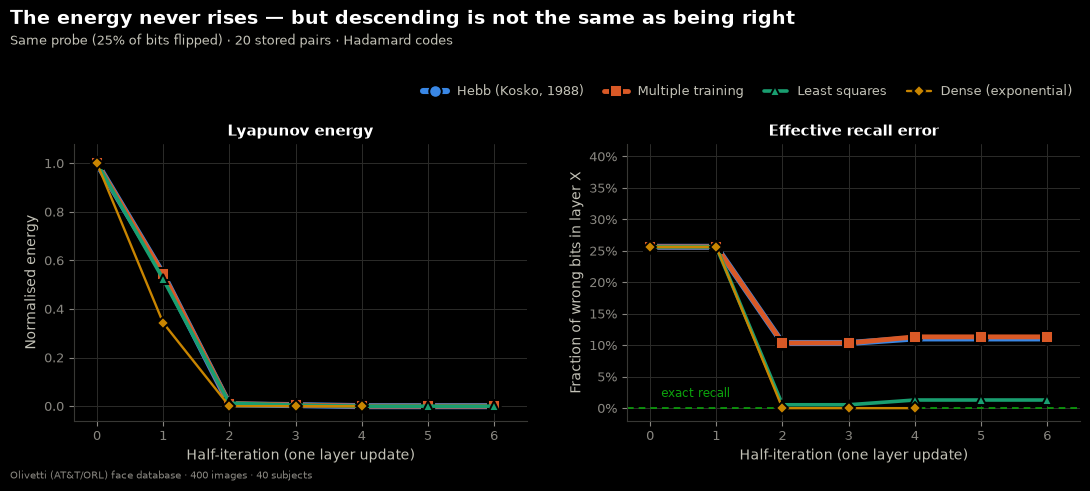


Checking energy monotonicity over 200 trajectories per rule...


               rule  trajectories  monotonicity_violations  convergence_rate  mean_energy_drop
 Hebb (Kosko, 1988)           200                        0               1.0      2.987803e+05
  Multiple training           200                        0               1.0      6.312368e+07
      Least squares           200                        0               1.0      4.596628e+02
Dense (exponential)           200                        0               1.0      1.470148e+00
------------------------------------------------------------------------------
  written: results/gifs/01_bidirectional_recall.gif
  written: results/figures/fig01_energy.png
  written: results/tables/tab01_lyapunov.csv
  total time: 24.4 s


In [22]:
def e1_main():
    t0 = header(
        1, "Bidirectional recall and the Lyapunov function",
        "Does the network converge? And does it converge to the right pair?",
    )
    data, X, Y = e1_setup()
    print(f"n = {X.shape[0]} bits per face · p = {Y.shape[0]} bits per code · "
          f"P = {X.shape[1]} stored pairs")

    rng = np.random.default_rng(SEED)
    j = 0
    probe = bit_flip_noise(X[:, j : j + 1], E1_NOISE, rng)[:, 0]
    print(f"Probe: face {j} with {int(E1_NOISE * 100)}% of its bits flipped "
          f"(initial Hamming = {float(normalized_hamming(probe, X[:, j])):.3f})")

    files = []
    for rule in RULES:
        model = BAM(rule, max_iter=E1_MAX_ITER).fit(X, Y)
        traj = model.recall(x0=probe)
        err = float(normalized_hamming(traj.x_final, X[:, j]))
        print(f"  {RULE_LABELS[rule]:22s} converged in {traj.n_iter} iterations · "
              f"final error = {err:.3f}")

    # The animation demonstrates the capability, so it uses the rule that
    # delivers it; the failure of the classical rule is the subject of the
    # static figure below and of every sweep in the other experiments.
    gif = bidirectional_recall_gif(
        BAM("dense", max_iter=E1_MAX_ITER).fit(X, Y),
        probe=probe, x_target=X[:, j], y_target=Y[:, j], side=data.side,
        name="01_bidirectional_recall",
        preroll=noise_preroll(X[:, j], E1_NOISE, SEED),
    )
    files.append(gif)
    files.append(e1_figure_energy(X, Y, probe, j))

    print(f"\nChecking energy monotonicity over {E1_N_LYAPUNOV_PROBES} "
          f"trajectories per rule...")
    table = e1_verify_lyapunov(X, Y)
    print(table.to_string(index=False))
    files.append(save_table(table, "tab01_lyapunov.csv"))

    footer(t0, files)
    apply_theme()
    return gif, table


e1_gif, e1_table = e1_main()

### Animação 1 — o que uma BAM realmente faz

Uma face corrompida entra; o par volta. Depois a face é apagada e o código
sozinho a restaura.

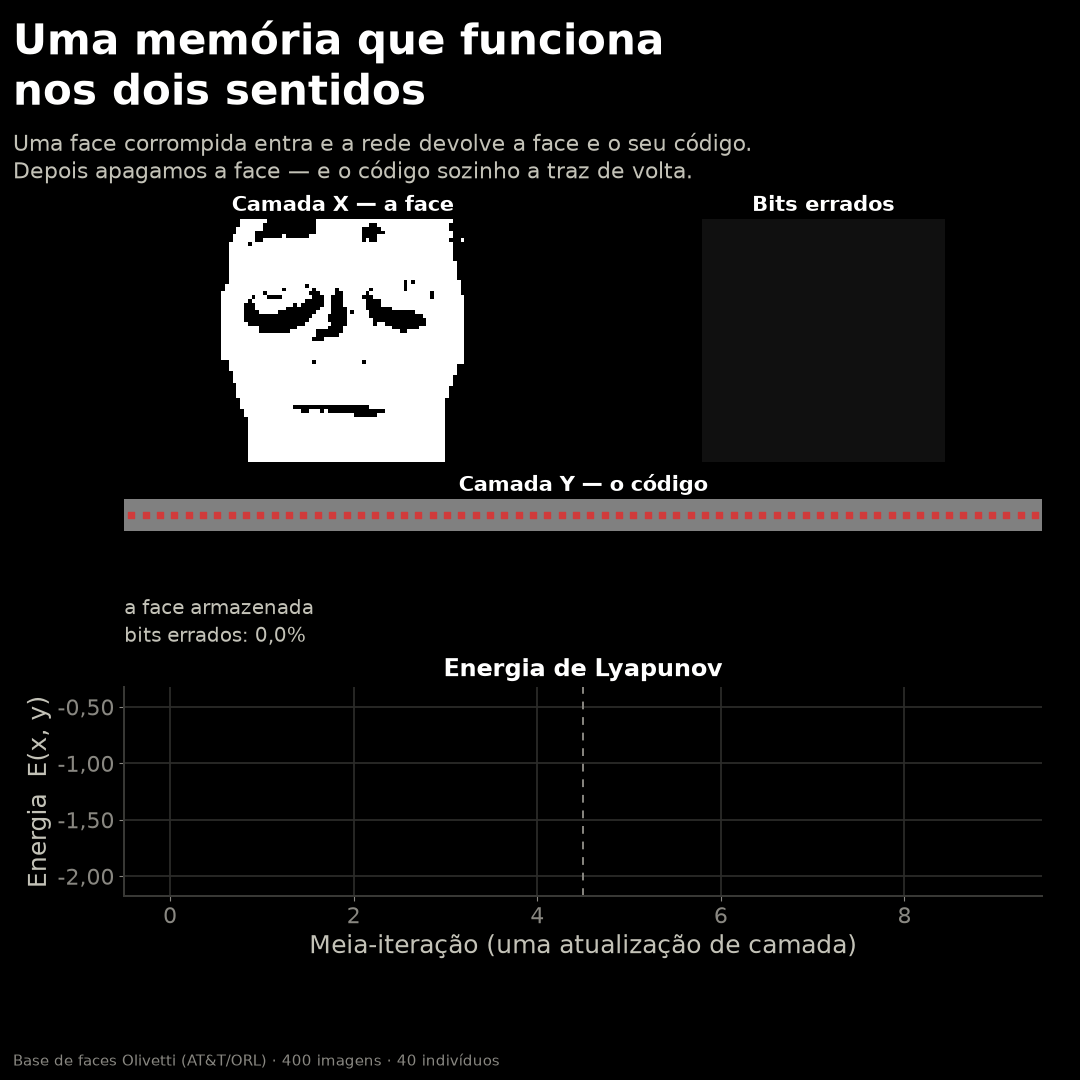

In [23]:
display(Image(str(e1_gif)))

---
# Parte 11 · Experimento 2 — Capacidade de armazenamento

## Pergunta

Quantos pares `(face, código)` uma BAM realmente armazena? Kosko (1988)
conjecturou $\min(n, p)$; para padrões aleatórios a análise assintótica dá
$\min(n,p) / (2\ln \min(n,p))$. Ambos os números pressupõem padrões não
correlacionados. **Faces reais não são não correlacionadas.** Este experimento
mede a capacidade efetiva ao longo de três eixos:

* **regra de aprendizagem** (4 regras);
* **codebook da camada Y** (Hadamard ortogonal vs. aleatório);
* **modo de recuperação** (passagem única vs. ressonância bidirecional completa).

O terceiro eixo é o que a literatura clássica não separa, e é decisivo: com
códigos de Hadamard a direção Y→X é *exata* em uma única passagem para
qualquer $P$, mas **a ressonância realimenta o erro da direção X→Y e destrói
esse resultado**.

**Saídas:** `02_capacity.gif`, `fig02_capacity.png`, `tab02_capacity*.csv`.

In [24]:
E2_CODE_LEN = 256  # code length: allows up to 255 Hadamard codes
E2_P_GRID = (5, 10, 20, 40, 60, 90, 120, 160, 200)
E2_CODEBOOKS = ("hadamard", "random")
E2_N_SEEDS = 6
E2_MAX_ITER = 20
E2_MAX_MT_EPOCHS = 30


def e2_sweep(data) -> pd.DataFrame:
    """Measure perfect-recall rate across the whole configuration grid."""
    rows = []
    total = len(E2_P_GRID) * len(E2_CODEBOOKS) * len(RULES) * E2_N_SEEDS
    done = 0
    for seed in range(E2_N_SEEDS):
        rng = np.random.default_rng(SEED + seed)
        # One fixed random order per seed: the sets of P pairs are nested (the
        # P=10 set contains the P=5 one), which makes the capacity curve a
        # genuine degradation rather than a fresh resample at every point.
        order = rng.permutation(data.n_patterns)
        for P in E2_P_GRID:
            X = data.X[:, order[:P]]
            for cb in E2_CODEBOOKS:
                Y = build_codebook(cb, P, E2_CODE_LEN, seed=SEED + seed)
                for rule in RULES:
                    model = BAM(rule, max_iter=E2_MAX_ITER,
                                max_mt_epochs=E2_MAX_MT_EPOCHS).fit(X, Y)
                    Xr, Yr, iters, converged = model.recall_batch(X0=X)
                    rows.append({
                        "seed": seed, "P": P, "codebook": cb, "rule": rule,
                        "forward_pass": perfect_recall_rate(
                            model.associate_forward(X), Y),
                        "backward_pass": perfect_recall_rate(
                            model.associate_backward(Y), X),
                        "resonance_x": perfect_recall_rate(Xr, X),
                        "resonance_y": perfect_recall_rate(Yr, Y),
                        "mean_iterations": float(iters.mean()),
                        "convergence": float(converged.mean()),
                    })
                    done += 1
        print(f"  seed {seed + 1}/{E2_N_SEEDS} — {done}/{total} configurations",
              flush=True)
    return pd.DataFrame(rows)


def e2_summarize(df: pd.DataFrame) -> pd.DataFrame:
    """Mean and 95 % CI half-width across seeds."""
    metrics = ["forward_pass", "backward_pass", "resonance_x", "resonance_y"]
    out = []
    for (P, cb, rule), g in df.groupby(["P", "codebook", "rule"], sort=False):
        row = {"P": P, "codebook": cb, "rule": rule}
        for m in metrics:
            mean, ci = confidence_interval(g[m].to_numpy())
            row[m], row[f"{m}_ci95"] = mean, ci
        out.append(row)
    return pd.DataFrame(out).sort_values(["codebook", "rule", "P"])


def e2_useful_capacity(res: pd.DataFrame, metric: str,
                       threshold: float = 0.95) -> pd.DataFrame:
    """Largest `P` on the grid at which the metric still reaches `threshold`."""
    out = []
    for (cb, rule), g in res.groupby(["codebook", "rule"], sort=False):
        ok = g.sort_values("P")
        ok = ok[ok[metric] >= threshold]["P"]
        out.append({"codebook": cb, "rule": rule, "metric": metric,
                    "useful_capacity": int(ok.max()) if len(ok) else 0})
    return pd.DataFrame(out)

In [25]:
def e2_figure_capacity(res: pd.DataFrame, n: int):
    """Small multiples: codebook down the rows, recall direction across."""
    apply_theme()
    columns = [
        ("forward_pass", "X→Y  (single pass)"),
        ("backward_pass", "Y→X  (single pass)"),
        ("resonance_x", "X  (full resonance)"),
    ]
    fig, axs = plt.subplots(len(E2_CODEBOOKS), len(columns), figsize=(12.4, 6.6),
                            sharex=True, sharey=True)
    fig.subplots_adjust(left=0.088, right=0.985, top=0.705, bottom=0.115,
                        hspace=0.30, wspace=0.10)

    for i, cb in enumerate(E2_CODEBOOKS):
        for j, (metric, title) in enumerate(columns):
            ax = axs[i, j]
            for order, rule in enumerate(RULES):
                g = res[(res.codebook == cb) & (res.rule == rule)].sort_values("P")
                x, y = g["P"].to_numpy(), g[metric].to_numpy()
                ci = g[f"{metric}_ci95"].to_numpy()
                color = RULE_COLOR[rule]
                ax.fill_between(x, y - ci, y + ci, color=color, alpha=0.16, lw=0,
                                zorder=2)
                # Decreasing line widths: coincident series (frequent here,
                # where several rules saturate at 0 % or 100 %) stay visible
                # under one another as a halo instead of vanishing.
                ax.plot(x, y, color=color, lw=5.2 - 1.1 * order,
                        marker=RULE_MARKER[rule], ms=8.5 - 1.0 * order,
                        markeredgecolor=SURFACE, markeredgewidth=1.2,
                        label=RULE_LABELS[rule], zorder=3 + order)
            ax.set_ylim(-0.04, 1.06)
            ax.yaxis.set_major_formatter(pct_fmt(0))
            if i == 0:
                ax.set_title(title, fontsize=10.5)
            if j == 0:
                ax.set_ylabel(f"{CODEBOOK_LABELS[cb]}\nperfect recall", fontsize=9.5)
            if i == len(E2_CODEBOOKS) - 1:
                ax.set_xlabel("Stored pairs  P")

    limit = asymptotic_bound(n, E2_CODE_LEN)
    for ax in axs.ravel():
        ax.axvline(limit, color=INK_MUTED, lw=1.1, ls=(0, (5, 4)), zorder=1)
    axs[-1, -1].annotate(
        f"asymptotic bound for\ni.i.d. patterns ≈ {limit:.0f} pairs",
        xy=(limit, 0.50), xytext=(10, 0), textcoords="offset points",
        fontsize=8.5, color=INK_MUTED, va="center",
    )

    handles, labels = axs[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", ncols=4,
               bbox_to_anchor=(0.988, 0.855), columnspacing=1.8, handlelength=1.9)

    figure_title(
        fig,
        "Real BAM capacity on faces: far below the classical conjecture",
        f"n = {n} · p = {E2_CODE_LEN} · Kosko's conjecture predicts "
        f"min(n, p) = {kosko_bound(n, E2_CODE_LEN)} pairs · mean of "
        f"{E2_N_SEEDS} seeds, band = 95 % CI",
    )
    credit(fig)
    target = FIGURES_DIR / "fig02_capacity.png"
    fig.savefig(target, dpi=160)
    plt.show()
    return target


def e2_capacity_gif(data, res: pd.DataFrame):
    """Square GIF: one variable changes — the codebook — and capacity moves 20×.

    Both rows use the same network and the same Hebb rule, and both are probed
    the same way: hand the network a stored code and ask for the face back. The
    only difference is whether the codes are mutually orthogonal.
    """
    rng = np.random.default_rng(SEED)
    order = rng.permutation(data.n_patterns)
    n_examples = 2
    shown = ("hadamard", "random")

    frames = []
    for P in E2_P_GRID:
        X = data.X[:, order[:P]]
        recovered = {}
        for cb in shown:
            Y = build_codebook(cb, P, E2_CODE_LEN, seed=SEED)
            model = BAM("hebb").fit(X, Y)
            recovered[cb] = model.associate_backward(Y)[:, :n_examples]
        frames.append((P, X[:, :n_examples], recovered))

    fig, top = new_square_figure("02_capacity")
    badge_y, top = top + 0.008, top - BADGE_GAP
    gs = fig.add_gridspec(
        3, n_examples, height_ratios=[1.0, 1.0, 1.15],
        left=0.135, right=0.965, top=top, bottom=PANEL_BOTTOM,
        hspace=0.38, wspace=0.08,
    )
    axes = {cb: [fig.add_subplot(gs[i, k]) for k in range(n_examples)]
            for i, cb in enumerate(shown)}
    ax_c = fig.add_subplot(gs[2, :])
    ax_c.set_xlim(0, max(E2_P_GRID) * 1.32)
    ax_c.set_ylim(-0.05, 1.10)
    ax_c.set_xlabel(AXIS_STORED_PAIRS)
    ax_c.set_ylabel(AXIS_PERFECT_RECALL, fontsize=13)
    ax_c.yaxis.set_major_formatter(pct_fmt(0, ptbr=True))

    curves = {
        cb: res[(res.codebook == cb) & (res.rule == "hebb")]
        .sort_values("P")[["P", "backward_pass"]].to_numpy()
        for cb in shown
    }

    movable: list = []

    def update(i: int) -> None:
        nonlocal movable
        for a in movable:
            a.remove()
        movable = []
        P, targets, recovered = frames[i]
        for cb in shown:
            for k, ax in enumerate(axes[cb]):
                ax.clear()
                ax.set_box_aspect(1.0)
                wrong = float((recovered[cb][:, k] != targets[:, k]).mean())
                caption = (EXACT_SHORT if wrong == 0 else
                           WRONG_SHORT.format(
                               value=format_percent(wrong, 1, ptbr=True)))
                face_panel(
                    ax, recovered[cb][:, k], data.side,
                    PT_CODEBOOKS[cb] if k == 0 else "", subtitle=caption,
                    border=GOOD if wrong == 0 else CRITICAL,
                    title_size=PANEL_TITLE_SIZE,
                    subtitle_size=PANEL_SUBTITLE_SIZE,
                )
        ends = []
        for order_c, cb in enumerate(shown):
            d = curves[cb]
            upto = int((d[:, 0] <= P).sum())
            movable.append(series_line(
                ax_c, d[:upto, 0], d[:upto, 1], color=CODEBOOK_COLOR[cb],
                marker="o" if cb == "hadamard" else "s", order=order_c))
            ends.append((d[upto - 1, 0], d[upto - 1, 1], PT_CODEBOOKS[cb]))
        movable += label_ends(ax_c, ends)
        movable.append(badge(fig, badge_y, STORED_PAIRS_COUNT.format(n=P)))
        if i == len(frames) - 1:
            movable += takeaway(fig, "02_capacity")

    return save_gif(fig, update, len(frames), "02_capacity",
                    fps=2, hold_first=2, hold_last=12)

### Execução

Esta é a varredura mais cara do estudo: 9 tamanhos de memória × 2 codebooks ×
4 regras × 6 sementes = 432 configurações. **~2 minutos.**


EXPERIMENT 2 — Storage capacity
Question: How many pairs does the BAM really hold, and what decides that number?
------------------------------------------------------------------------------
n = 4096 · p = 256 · P grid = [5, 10, 20, 40, 60, 90, 120, 160, 200] · 6 seeds
Kosko's conjecture: min(n, p) = 256 pairs
Asymptotic i.i.d. bound: 23 pairs



  seed 1/6 — 72/432 configurations


  seed 2/6 — 144/432 configurations


  seed 3/6 — 216/432 configurations


  seed 4/6 — 288/432 configurations


  seed 5/6 — 360/432 configurations


  seed 6/6 — 432/432 configurations



Useful capacity (largest P with >= 95 % perfect recall):
metric                      backward_pass  forward_pass  resonance_x
codebook rule                                                       
hadamard dense                      200.0         160.0        200.0
         hebb                       200.0           0.0          0.0
         least_squares               10.0           5.0          5.0
         multiple_training          200.0           0.0          0.0
random   dense                      200.0         160.0        200.0
         hebb                        10.0           0.0          0.0
         least_squares               10.0           5.0         10.0
         multiple_training           10.0           0.0          0.0

Highlights:
  Hadamard (orthogonal)  Hebb (Kosko, 1988)     P=200: X→Y 0.00 · Y→X 1.00 · resonance 0.00
  Hadamard (orthogonal)  Multiple training      P=200: X→Y 0.00 · Y→X 1.00 · resonance 0.00
  Hadamard (orthogonal)  Least squares          P=200: 

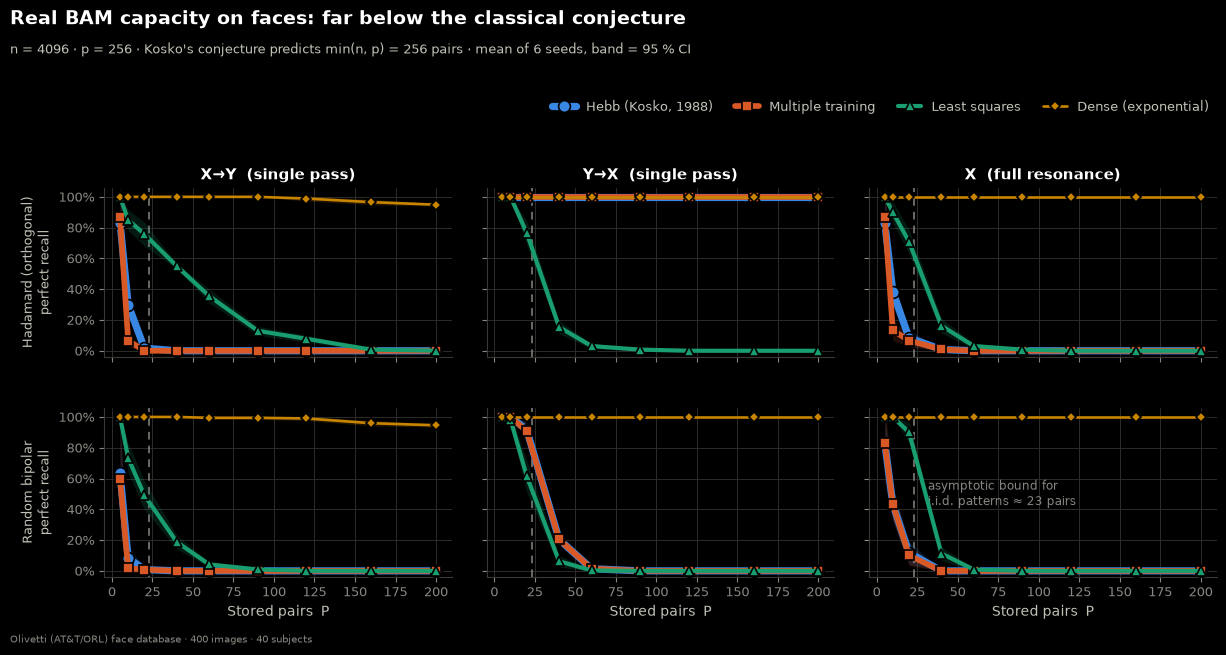

------------------------------------------------------------------------------
  written: results/tables/tab02_capacity.csv
  written: results/tables/tab02_capacity_summary.csv
  written: results/tables/tab02_useful_capacity.csv
  written: results/figures/fig02_capacity.png
  written: results/gifs/02_capacity.gif
  total time: 104.1 s


In [26]:
def e2_main():
    t0 = header(
        2, "Storage capacity",
        "How many pairs does the BAM really hold, and what decides that number?",
    )
    data = load_dataset(method="mean-face")
    print(f"n = {data.n} · p = {E2_CODE_LEN} · P grid = {list(E2_P_GRID)} · "
          f"{E2_N_SEEDS} seeds")
    print(f"Kosko's conjecture: min(n, p) = "
          f"{kosko_bound(data.n, E2_CODE_LEN)} pairs")
    print(f"Asymptotic i.i.d. bound: "
          f"{asymptotic_bound(data.n, E2_CODE_LEN):.0f} pairs\n")

    df = e2_sweep(data)
    res = e2_summarize(df)

    files = [save_table(df, "tab02_capacity.csv"),
             save_table(res, "tab02_capacity_summary.csv")]

    caps = pd.concat([e2_useful_capacity(res, m)
                      for m in ("forward_pass", "backward_pass", "resonance_x")])
    files.append(save_table(caps, "tab02_useful_capacity.csv"))

    print("\nUseful capacity (largest P with >= 95 % perfect recall):")
    print(caps.pivot_table(index=["codebook", "rule"], columns="metric",
                           values="useful_capacity").to_string())

    print("\nHighlights:")
    for cb in E2_CODEBOOKS:
        for rule in RULES:
            g = res[(res.codebook == cb) & (res.rule == rule)]
            top_row = g[max(E2_P_GRID) == g.P].iloc[0]
            print(f"  {CODEBOOK_LABELS[cb]:22s} {RULE_LABELS[rule]:22s} "
                  f"P={max(E2_P_GRID)}: X→Y {top_row.forward_pass:.2f} · "
                  f"Y→X {top_row.backward_pass:.2f} · "
                  f"resonance {top_row.resonance_x:.2f}")

    files.append(e2_figure_capacity(res, data.n))
    gif = e2_capacity_gif(data, res)
    files.append(gif)
    footer(t0, files)
    apply_theme()
    return gif, res, caps


e2_gif, e2_res, e2_caps = e2_main()

### Animação 2 — quantos pares cabem?

A mesma rede, a mesma regra — só o codebook muda, e a capacidade se move 20×.

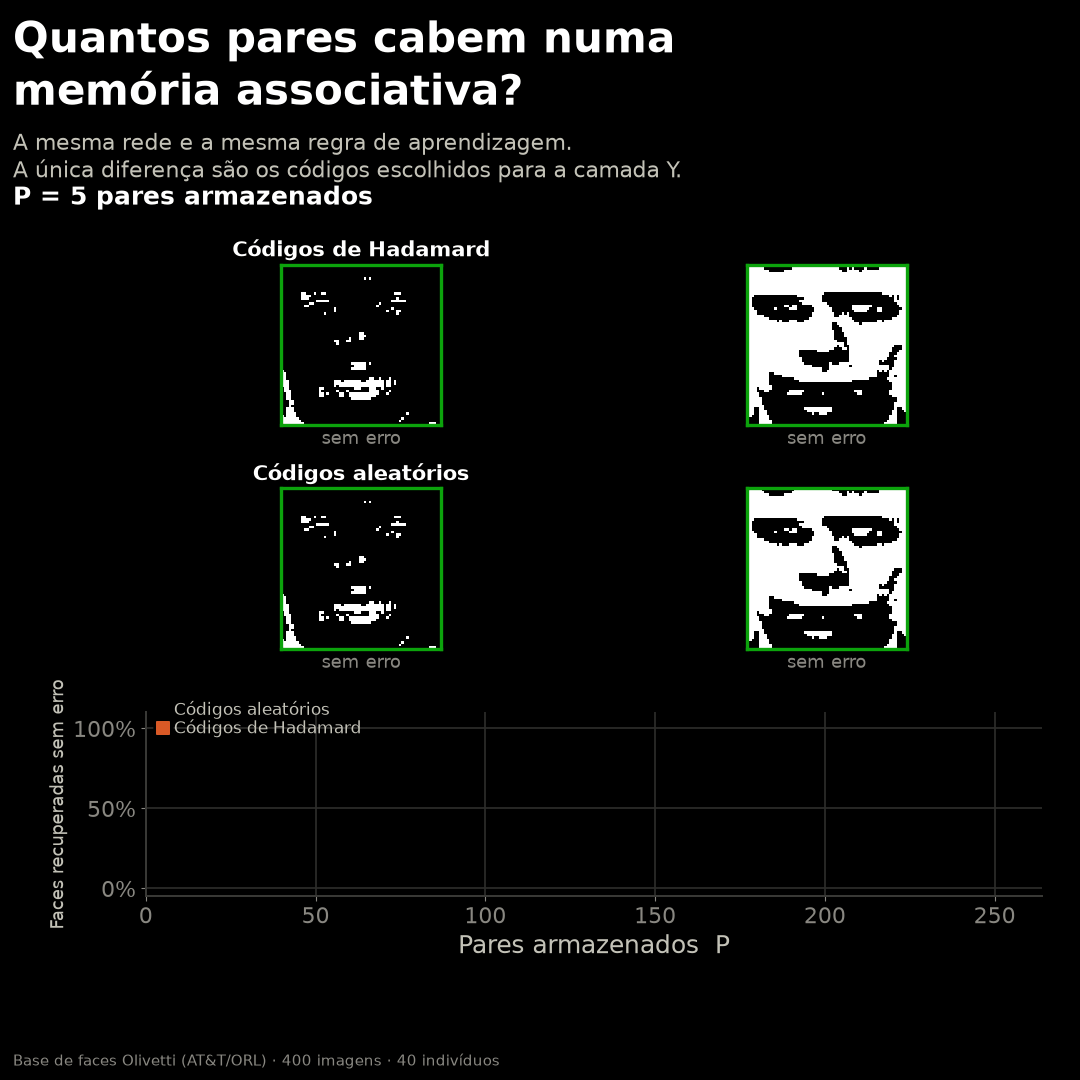

In [27]:
display(Image(str(e2_gif)))

---
# Parte 12 · Experimento 3 — Robustez a ruído e oclusão

## Pergunta

Uma memória endereçável por conteúdo só é útil se a sonda puder estar
corrompida. Quão grande é a bacia de atração de cada regra, e ela é a mesma
nos dois sentidos?

Três modos de corrupção são varridos:

**A. Ruído de bits na face** — cada pixel é invertido com probabilidade $q$.
Corrupção *ativa*: a sonda afirma coisas erradas.

**B. Oclusão da face** — as linhas inferiores da imagem são zeradas. Corrupção
*passiva*: os pixels ocultos entram com campo local zero, isto é, a sonda
apenas se cala. Uma BAM deveria tolerar muito mais oclusão do que ruído, e o
experimento mede quanto.

**C. Ruído de bits no código** — a corrupção atinge a camada Y. É a direção em
que os códigos de Hadamard tornam a BAM hebbiana exata, e onde a regra clássica
finalmente se defende bem.

**Saídas:** `03_robustness.gif`, `fig03_robustness.png`, `tab03_*.csv`.

In [28]:
E3_P = 20
E3_CODE_LEN = 64
E3_N_SEEDS = 6
E3_MAX_ITER = 20
E3_NOISE_LEVELS = np.round(np.arange(0.0, 0.51, 0.05), 3)
E3_OCCLUSION_LEVELS = np.round(np.arange(0.0, 0.91, 0.10), 3)
E3_CODE_NOISE_LEVELS = np.round(np.arange(0.0, 0.51, 0.05), 3)
E3_GIF_LEVELS = np.round(np.arange(0.0, 0.81, 0.10), 3)

# Panel title: the scenario name plus the recall mode being measured, so the
# reader never has to hunt for that information in a floating note.
E3_PANEL_TITLES = {
    "noise_x": "Bit noise on the face\nrecall by resonance",
    "occlusion_x": "Occlusion of the face\nrecall by resonance",
    "noise_y": "Bit noise on the code\nsingle-pass Y→X recall",
}


def e3_row(seed, scenario, level, rule, Xr, X, Yp, Y) -> dict:
    """One result row for the scenarios that corrupt layer X."""
    return {
        "seed": seed,
        "scenario": scenario,
        "level": float(level),
        "rule": rule,
        "x_perfect_resonance": perfect_recall_rate(Xr, X),
        "x_bits_resonance": bit_accuracy(Xr, X),
        "y_perfect_pass": perfect_recall_rate(Yp, Y),
        "y_bits_pass": bit_accuracy(Yp, Y),
    }


def e3_sweep(data) -> pd.DataFrame:
    """Measure recall under the three corruption scenarios."""
    idx = one_index_per_subject(data.target)[:E3_P]
    X = data.X[:, idx]
    rows = []
    for seed in range(E3_N_SEEDS):
        rng = np.random.default_rng(SEED + 100 * seed)
        Y = build_codebook("hadamard", E3_P, E3_CODE_LEN)
        models = {r: BAM(r, max_iter=E3_MAX_ITER).fit(X, Y) for r in RULES}
        for rule, model in models.items():
            for level in E3_NOISE_LEVELS:
                probe = bit_flip_noise(X, float(level), rng)
                Xr, Yr, _, _ = model.recall_batch(X0=probe)
                rows.append(e3_row(seed, "noise_x", level, rule, Xr, X,
                                   model.associate_forward(probe), Y))
            for level in E3_OCCLUSION_LEVELS:
                probe = occlude(X, float(level), data.side)
                Xr, Yr, _, _ = model.recall_batch(X0=probe)
                rows.append(e3_row(seed, "occlusion_x", level, rule, Xr, X,
                                   model.associate_forward(probe), Y))
            for level in E3_CODE_NOISE_LEVELS:
                probe_y = bit_flip_noise(Y, float(level), rng)
                Xp = model.associate_backward(probe_y)
                Xr, Yr, _, _ = model.recall_batch(Y0=probe_y)
                rows.append({
                    "seed": seed, "scenario": "noise_y", "level": float(level),
                    "rule": rule,
                    "x_perfect_pass": perfect_recall_rate(Xp, X),
                    "x_bits_pass": bit_accuracy(Xp, X),
                    "x_perfect_resonance": perfect_recall_rate(Xr, X),
                    "y_perfect_pass": perfect_recall_rate(Yr, Y),
                })
        print(f"  seed {seed + 1}/{E3_N_SEEDS}", flush=True)
    return pd.DataFrame(rows)


def e3_summarize(df: pd.DataFrame) -> pd.DataFrame:
    """Mean and 95 % CI across seeds, for whichever metrics are present."""
    metrics = [c for c in df.columns
               if c not in ("seed", "scenario", "level", "rule")]
    out = []
    for (sc, level, rule), g in df.groupby(["scenario", "level", "rule"],
                                           sort=False):
        row = {"scenario": sc, "level": level, "rule": rule}
        for m in metrics:
            values = g[m].dropna().to_numpy()
            if values.size:
                mean, ci = confidence_interval(values)
                row[m], row[f"{m}_ci95"] = mean, ci
        out.append(row)
    return pd.DataFrame(out)


def e3_critical_level(res: pd.DataFrame, scenario: str, metric: str,
                      threshold: float = 0.90) -> pd.DataFrame:
    """Largest corruption level at which the metric still reaches `threshold`."""
    out = []
    for rule, g in res[res.scenario == scenario].groupby("rule", sort=False):
        ok = g.sort_values("level")
        ok = ok[ok[metric] >= threshold]["level"]
        out.append({"scenario": scenario, "rule": rule, "metric": metric,
                    "critical_level": float(ok.max()) if len(ok) else float("nan")})
    return pd.DataFrame(out)

In [29]:
def e3_figure_robustness(res: pd.DataFrame):
    """Small multiples: one corruption scenario per column."""
    apply_theme()
    panels = [
        ("noise_x", "x_perfect_resonance", "Fraction of face bits flipped"),
        ("occlusion_x", "x_perfect_resonance", "Fraction of the face occluded"),
        ("noise_y", "x_perfect_pass", "Fraction of code bits flipped"),
    ]
    fig, axs = plt.subplots(1, 3, figsize=(12.4, 4.9), sharey=True)
    fig.subplots_adjust(left=0.072, right=0.985, top=0.60, bottom=0.155,
                        wspace=0.09)

    for ax, (sc, metric, xlabel) in zip(axs, panels, strict=True):
        for order, rule in enumerate(RULES):
            g = res[(res.scenario == sc) & (res.rule == rule)].sort_values("level")
            x, y = g["level"].to_numpy(), g[metric].to_numpy()
            ci = g[f"{metric}_ci95"].to_numpy()
            color = RULE_COLOR[rule]
            ax.fill_between(x, y - ci, y + ci, color=color, alpha=0.16, lw=0,
                            zorder=2)
            ax.plot(x, y, color=color, lw=5.2 - 1.1 * order,
                    marker=RULE_MARKER[rule], ms=8.5 - 1.0 * order,
                    markeredgecolor=SURFACE, markeredgewidth=1.2,
                    label=RULE_LABELS[rule], zorder=3 + order)
        ax.set_xlabel(xlabel)
        ax.set_ylim(-0.04, 1.06)
        ax.xaxis.set_major_formatter(pct_fmt(0))
        ax.yaxis.set_major_formatter(pct_fmt(0))
        ax.set_title(E3_PANEL_TITLES[sc], fontsize=10.5, linespacing=1.5)
    axs[0].set_ylabel("Faces recalled with no wrong bit")

    handles, labels = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", ncols=4,
               bbox_to_anchor=(0.988, 0.845), columnspacing=1.8, handlelength=1.9)
    figure_title(
        fig,
        "BAM robustness depends on which layer gets corrupted",
        f"P = {E3_P} stored pairs · Hadamard codes · mean of {E3_N_SEEDS} seeds, "
        f"band = 95 % CI",
    )
    credit(fig)
    target = FIGURES_DIR / "fig03_robustness.png"
    fig.savefig(target, dpi=160)
    plt.show()
    return target


def e3_robustness_gif(data):
    """Square GIF contrasting the two ways of destroying the probe.

    Both columns are damaged by the same fraction at the same time, so the
    comparison is a controlled one: what changes is only *how* the pixels are
    lost. Flipped pixels assert the opposite of the truth; erased pixels merely
    fall silent, entering the network with zero local field.

    The curves are computed here rather than read from the statistical sweep so
    that the animation and its plot describe exactly the same runs.
    """
    idx = one_index_per_subject(data.target)[:E3_P]
    X = data.X[:, idx]
    Y = build_codebook("hadamard", E3_P, E3_CODE_LEN)
    model = BAM("dense", max_iter=E3_MAX_ITER).fit(X, Y)
    n_examples = 2
    rng = np.random.default_rng(SEED)
    draw = rng.random(X.shape)  # cumulative mask: the noise only grows

    kinds = ("noise", "occlusion")
    labels = {"noise": NOISE_LABEL, "occlusion": OCCLUSION_LABEL}
    colors = {"noise": SERIES[1], "occlusion": SERIES[2]}
    markers = {"noise": "o", "occlusion": "^"}

    frames, curves = [], {k: [] for k in kinds}
    for level in E3_GIF_LEVELS:
        probes, recovered = {}, {}
        for kind in kinds:
            probe = (np.where(draw < level, -X, X) if kind == "noise"
                     else occlude(X, float(level), data.side))
            Xr, _, _, _ = model.recall_batch(X0=probe)
            probes[kind] = probe[:, :n_examples]
            recovered[kind] = Xr[:, :n_examples]
            curves[kind].append(perfect_recall_rate(Xr, X))
        frames.append((float(level), probes, recovered))
    curves = {k: np.column_stack([E3_GIF_LEVELS, v]) for k, v in curves.items()}

    fig, top = new_square_figure("03_robustness")
    badge_y, top = top + 0.008, top - BADGE_GAP
    gs = fig.add_gridspec(
        3, 2, height_ratios=[1.0, 1.0, 1.15],
        left=0.135, right=0.965, top=top, bottom=PANEL_BOTTOM,
        hspace=0.38, wspace=0.10,
    )
    ax_probe = [fig.add_subplot(gs[0, k]) for k in range(2)]
    ax_out = [fig.add_subplot(gs[1, k]) for k in range(2)]
    ax_c = fig.add_subplot(gs[2, :])
    ax_c.set_xlim(-0.02, float(max(E3_GIF_LEVELS)) * 1.34)
    ax_c.set_ylim(-0.05, 1.10)
    ax_c.set_xlabel(AXIS_CORRUPTION)
    ax_c.set_ylabel(AXIS_PERFECT_RECALL, fontsize=13)
    ax_c.xaxis.set_major_formatter(pct_fmt(0, ptbr=True))
    ax_c.yaxis.set_major_formatter(pct_fmt(0, ptbr=True))

    movable: list = []

    def update(i: int) -> None:
        nonlocal movable
        for a in movable:
            a.remove()
        movable = []
        level, probes, recovered = frames[i]
        for col, kind in enumerate(kinds):
            for ax in (ax_probe[col], ax_out[col]):
                ax.clear()
                ax.set_box_aspect(1.0)
            face_panel(ax_probe[col], probes[kind][:, 0], data.side,
                       labels[kind], border=INK_MUTED,
                       title_size=PANEL_TITLE_SIZE)
            wrong = float((recovered[kind][:, 0] != X[:, 0]).mean())
            caption = (EXACT_SHORT if wrong == 0 else
                       WRONG_SHORT.format(
                           value=format_percent(wrong, 1, ptbr=True)))
            face_panel(ax_out[col], recovered[kind][:, 0], data.side,
                       PANEL_RECOVERED, subtitle=caption,
                       border=GOOD if wrong == 0 else CRITICAL,
                       title_size=PANEL_TITLE_SIZE,
                       subtitle_size=PANEL_SUBTITLE_SIZE)
        ends = []
        for order, kind in enumerate(kinds):
            d = curves[kind]
            movable.append(series_line(ax_c, d[: i + 1, 0], d[: i + 1, 1],
                                       color=colors[kind], marker=markers[kind],
                                       order=order))
            ends.append((d[i, 0], d[i, 1], labels[kind].split(" —")[0]))
        movable += label_ends(ax_c, ends)
        movable.append(badge(fig, badge_y, CORRUPTION_LEVEL.format(
            value=format_percent(level, 0, ptbr=True))))
        if i == len(frames) - 1:
            movable += takeaway(fig, "03_robustness")

    return save_gif(fig, update, len(frames), "03_robustness",
                    fps=2, hold_first=2, hold_last=12)


EXPERIMENT 3 — Robustness to noise and occlusion
Question: How much corruption does the probe tolerate, and does the answer change with the corrupted layer?
------------------------------------------------------------------------------
P = 20 pairs · p = 64 · Hadamard codes · 6 seeds



  seed 1/6


  seed 2/6


  seed 3/6


  seed 4/6


  seed 5/6


  seed 6/6



Maximum corruption tolerated with >= 90 % perfect recall:
scenario           noise_x  noise_y  occlusion_x
rule                                            
dense                 0.45     0.25          0.8
hebb                     —     0.00            —
least_squares         0.35     0.00          0.4
multiple_training        —     0.00            —

Fragility of exactness (Y→X direction, single pass):
  Hebb (Kosko, 1988)     noise-free 1.00 → with 10 % code noise 0.29
  Multiple training      noise-free 1.00 → with 10 % code noise 0.33
  Least squares          noise-free 0.90 → with 10 % code noise 0.05
  Dense (exponential)    noise-free 1.00 → with 10 % code noise 1.00


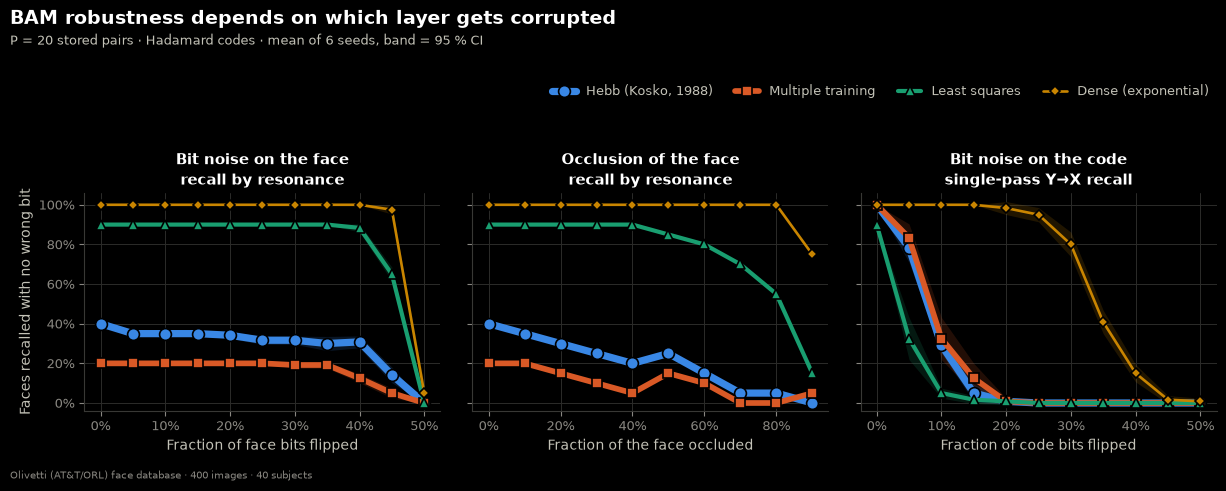

------------------------------------------------------------------------------
  written: results/tables/tab03_robustness.csv
  written: results/tables/tab03_robustness_summary.csv
  written: results/tables/tab03_critical_levels.csv
  written: results/figures/fig03_robustness.png
  written: results/gifs/03_robustness.gif
  total time: 20.1 s


In [30]:
def e3_main():
    t0 = header(
        3, "Robustness to noise and occlusion",
        "How much corruption does the probe tolerate, and does the answer "
        "change with the corrupted layer?",
    )
    data = load_dataset(method="mean-face")
    print(f"P = {E3_P} pairs · p = {E3_CODE_LEN} · Hadamard codes · "
          f"{E3_N_SEEDS} seeds\n")

    df = e3_sweep(data)
    res = e3_summarize(df)
    files = [save_table(df, "tab03_robustness.csv"),
             save_table(res, "tab03_robustness_summary.csv")]

    critical = pd.concat([
        e3_critical_level(res, "noise_x", "x_perfect_resonance"),
        e3_critical_level(res, "occlusion_x", "x_perfect_resonance"),
        e3_critical_level(res, "noise_y", "x_perfect_pass"),
    ])
    files.append(save_table(critical, "tab03_critical_levels.csv"))

    print("\nMaximum corruption tolerated with >= 90 % perfect recall:")
    print(critical.pivot_table(index="rule", columns="scenario",
                               values="critical_level").to_string(na_rep="—"))

    print("\nFragility of exactness (Y→X direction, single pass):")
    for rule in RULES:
        g = res[(res.scenario == "noise_y") & (res.rule == rule)]
        clean = float(g[g.level == 0.0].iloc[0]["x_perfect_pass"])
        ten = float(g[g.level == 0.10].iloc[0]["x_perfect_pass"])
        print(f"  {RULE_LABELS[rule]:22s} noise-free {clean:.2f} → "
              f"with 10 % code noise {ten:.2f}")

    files.append(e3_figure_robustness(res))
    gif = e3_robustness_gif(data)
    files.append(gif)
    footer(t0, files)
    apply_theme()
    return gif, res, critical


e3_gif, e3_res, e3_critical = e3_main()

### Animação 3 — quanto dano sobrevive?

Pixels invertidos contra pixels apagados, corrompidos na mesma fração ao mesmo
tempo.

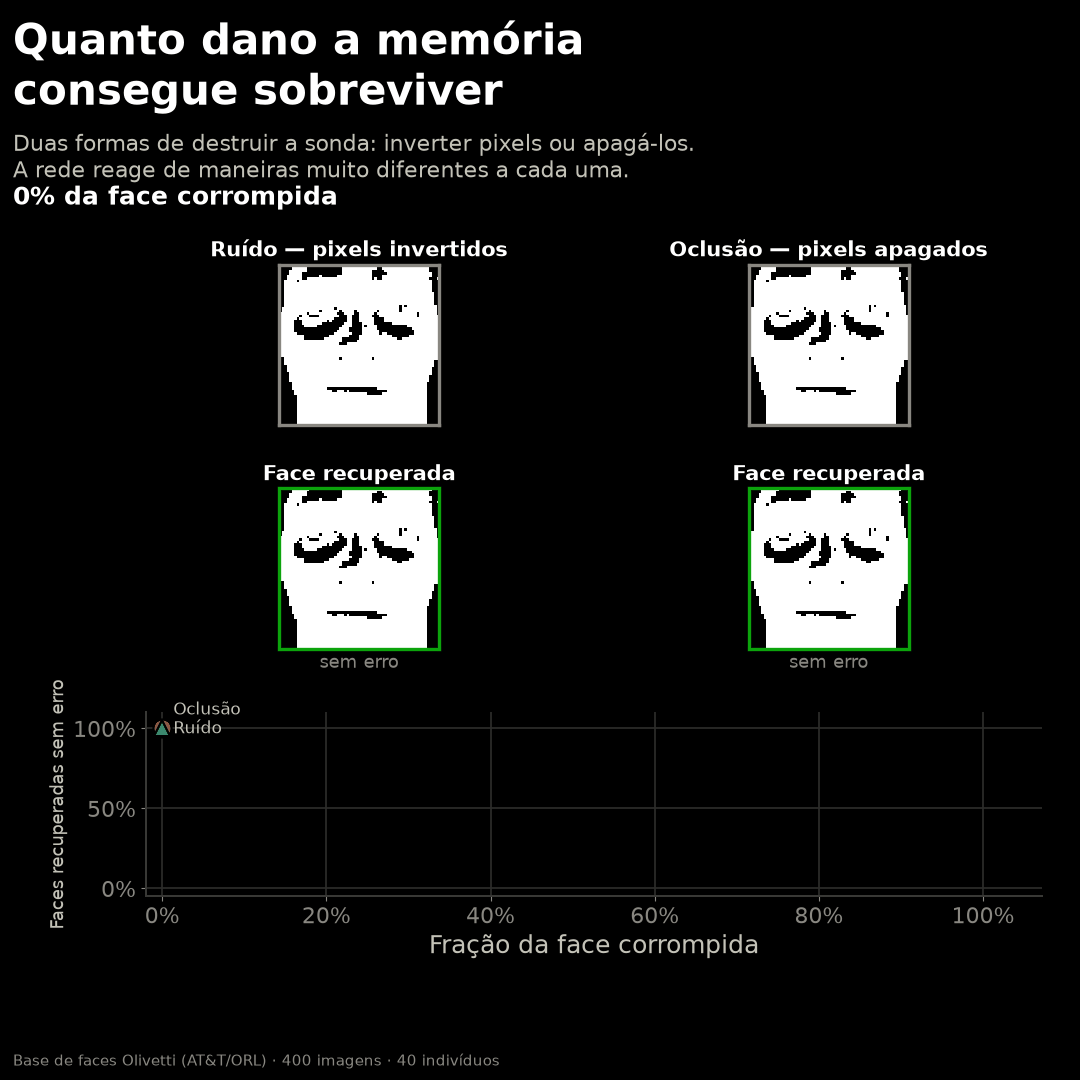

In [31]:
display(Image(str(e3_gif)))

---
# Parte 13 · Experimento 4 — *Crosstalk*: prever o erro antes de medi-lo

## Pergunta

Os Experimentos 2 e 3 mostram **que** a BAM clássica falha em faces. Este
mostra **por quê**, e verifica se o mecanismo proposto prevê o erro observado
quantitativamente.

O modelo é a razão sinal-ruído do *crosstalk* (Parte 6): sondando com um padrão
armazenado, o campo local é o sinal desejado mais a interferência somada de
todos os outros padrões, cuja magnitude é fixada pelas correlações entre eles.
Se o modelo estiver certo, a taxa de erro por bit medida deve seguir
$\Phi(-\mathrm{SNR})$ **sem nenhum parâmetro ajustado**.

Três vertentes:

**A. Validação** — erro por bit previsto vs. observado, ao longo de duas
binarizações, dois codebooks, dois sentidos e nove tamanhos de memória.

**B. Descorrelacionar os dados ajuda?** Comparação direta entre limiarizar cada
face na sua própria mediana e na face média da base.

**C. A fronteira de compromisso** — a regra de mínimos quadrados tem um peso
$\lambda$ que divide a capacidade de ajuste entre os dois sentidos. Nenhum $W$
acerta os dois exatamente; o que existe é uma **fronteira de Pareto**, e este
experimento a mede.

Este é o núcleo analítico do estudo e não produz animação: seu resultado é um
gráfico de dispersão de previsões contra medições, que se lê, não se assiste.

**Saídas:** `fig04_crosstalk.png`, `fig05_tradeoff.png`, `tab04_*.csv`.

In [32]:
E4_CODE_LEN = 256
E4_P_GRID = (5, 10, 20, 40, 60, 90, 120, 160, 200)
E4_BINARIZATIONS = ("median", "mean-face")
E4_CODEBOOKS = ("hadamard", "random")

E4_P_TRADEOFF = 20
E4_CODE_LEN_TRADEOFF = 64
E4_LAMBDA_GRID = np.round(np.linspace(0.0, 1.0, 21), 3)

E4_BIN_COLOR = {"median": SERIES[1], "mean-face": SERIES[0]}
E4_DIRECTION_MARKER = {"X→Y": "o", "Y→X": "^"}
E4_BIN_SHORT = {"median": "median threshold", "mean-face": "mean-face threshold"}
E4_BIN_TINY = {"median": "median", "mean-face": "mean face"}


def e4_validate_theory() -> pd.DataFrame:
    """Predicted vs. observed per-bit error, for the Hebb rule.

    Only the Hebb rule enters here: it is the one the crosstalk theory was
    derived for. The other rules do not have the form `W = Σ x_k y_kᵀ` and
    therefore admit no such signal-plus-interference decomposition.
    """
    rows = []
    for method in E4_BINARIZATIONS:
        data = load_dataset(method=method)
        rng = np.random.default_rng(SEED)
        order = rng.permutation(data.n_patterns)
        for P in E4_P_GRID:
            X = data.X[:, order[:P]]
            for cb in E4_CODEBOOKS:
                Y = build_codebook(cb, P, E4_CODE_LEN, seed=SEED)
                model = BAM("hebb").fit(X, Y)
                Yhat = model.associate_forward(X)
                Xhat = model.associate_backward(Y)

                rows.append({
                    "binarization": method, "codebook": cb, "P": P,
                    "direction": "X→Y",
                    "snr": float(np.mean(crosstalk_snr(X))),
                    "predicted_error": float(np.mean(
                        predicted_bit_error(crosstalk_snr(X)))),
                    "observed_error": float((Yhat != Y).mean()),
                    "observed_perfect": perfect_recall_rate(Yhat, Y),
                    "mean_correlation": mean_correlation(X),
                    "code_orthogonality": orthogonality(Y),
                })
                snr_y = crosstalk_snr(Y)
                rows.append({
                    "binarization": method, "codebook": cb, "P": P,
                    "direction": "Y→X",
                    "snr": float(np.mean(snr_y[np.isfinite(snr_y)]))
                           if np.isfinite(snr_y).any() else float("inf"),
                    "predicted_error": float(np.mean(predicted_bit_error(snr_y))),
                    "observed_error": float((Xhat != X).mean()),
                    "observed_perfect": perfect_recall_rate(Xhat, X),
                    "mean_correlation": mean_correlation(X),
                    "code_orthogonality": orthogonality(Y),
                })
    return pd.DataFrame(rows)


def e4_sweep_tradeoff():
    """Pareto frontier between the two directions, sweeping `λ`."""
    data = load_dataset(method="mean-face")
    rng = np.random.default_rng(SEED)
    order = rng.permutation(data.n_patterns)
    X = data.X[:, order[:E4_P_TRADEOFF]]
    Y = build_codebook("hadamard", E4_P_TRADEOFF, E4_CODE_LEN_TRADEOFF)
    rows = []
    for lam in E4_LAMBDA_GRID:
        model = BAM("least_squares", lam=float(lam), max_iter=20).fit(X, Y)
        Xr, Yr, _, _ = model.recall_batch(X0=X)
        rows.append({
            "lambda": float(lam),
            "forward_pass": perfect_recall_rate(model.associate_forward(X), Y),
            "backward_pass": perfect_recall_rate(model.associate_backward(Y), X),
            "resonance_x": perfect_recall_rate(Xr, X),
            "resonance_y": perfect_recall_rate(Yr, Y),
        })
    return pd.DataFrame(rows), data, X, Y

In [33]:
def e4_figure_crosstalk(df: pd.DataFrame):
    """Panel A: SNR against P. Panel B: predicted vs. observed error."""
    apply_theme()
    fig, (ax_s, ax_v) = plt.subplots(1, 2, figsize=(11.6, 5.0))
    fig.subplots_adjust(left=0.075, right=0.985, top=0.665, bottom=0.135,
                        wspace=0.24)

    # --- A: X→Y SNR collapses; Y→X SNR depends on the codebook
    for method in E4_BINARIZATIONS:
        g = df[(df.binarization == method) & (df.direction == "X→Y")
               & (df.codebook == "hadamard")].sort_values("P")
        ax_s.plot(g["P"], g["snr"], color=E4_BIN_COLOR[method], lw=2.4, marker="o",
                  ms=7, markeredgecolor=SURFACE, markeredgewidth=1.2,
                  label=f"X→Y · {E4_BIN_SHORT[method]}")
    g = df[(df.direction == "Y→X") & (df.codebook == "random")
           & (df.binarization == "mean-face")].sort_values("P")
    ax_s.plot(g["P"], g["snr"], color=SERIES[2], lw=2.4, marker="^", ms=7,
              markeredgecolor=SURFACE, markeredgewidth=1.2,
              label="Y→X · random codebook")

    ax_s.axhline(2.0, color=INK_MUTED, lw=1.1, ls=(0, (5, 4)), zorder=1)
    ax_s.annotate("SNR = 2  (≈ 2 % error per bit)", xy=(max(E4_P_GRID), 2.0),
                  xytext=(-4, 6), textcoords="offset points", ha="right",
                  fontsize=8.5, color=INK_MUTED)
    ax_s.set_yscale("log")
    ax_s.set_xlabel("Stored pairs  P")
    ax_s.set_ylabel("Crosstalk signal-to-noise ratio")
    ax_s.set_title("Crosstalk grows with the memory", fontsize=10.5)
    ax_s.legend(loc="upper right", fontsize=8.5)

    # --- B: parameter-free validation
    g = df[np.isfinite(df.predicted_error)]
    for direction, marker in E4_DIRECTION_MARKER.items():
        for method in E4_BINARIZATIONS:
            sub = g[(g.direction == direction) & (g.binarization == method)]
            ax_v.scatter(sub["predicted_error"], sub["observed_error"], s=48,
                         marker=marker, color=E4_BIN_COLOR[method],
                         edgecolors=SURFACE, linewidths=1.1, zorder=3,
                         label=f"{direction} · {E4_BIN_TINY[method]}")
    lim = [1e-4, 0.6]
    ax_v.plot(lim, lim, color=INK_MUTED, lw=1.2, ls=(0, (5, 4)), zorder=2)
    ax_v.annotate("exact prediction", xy=(0.02, 0.02), xytext=(9, -4),
                  textcoords="offset points", fontsize=8.5, color=INK_MUTED,
                  rotation=45, rotation_mode="anchor")
    ax_v.set_xscale("log")
    ax_v.set_yscale("log")
    ax_v.set_xlim(*lim)
    ax_v.set_ylim(*lim)
    ax_v.set_xlabel("Predicted error per bit  Φ(−SNR)")
    ax_v.set_ylabel("Observed error per bit")
    ax_v.set_title("The theory predicts the error with no fitted parameter",
                   fontsize=10.5)
    ax_v.legend(loc="upper left", fontsize=8, ncols=2)

    figure_title(
        fig,
        "Why the classical BAM fails on faces: crosstalk",
        "Hebb rule · n = 4096 · p = 256 · points span 9 memory sizes × "
        "2 binarisations × 2 codebooks",
    )
    # The Hadamard case does not fit on the left plot: its SNR is infinite, and
    # a log axis has nowhere to put infinity. It is stated in the header.
    fig.text(0.012, 0.875,
             "With a Hadamard codebook the Y→X SNR is infinite — crosstalk "
             "cancels exactly, not merely on average.",
             ha="left", va="top", fontsize=9, color=SERIES[2])
    credit(fig)
    target = FIGURES_DIR / "fig04_crosstalk.png"
    fig.savefig(target, dpi=160)
    plt.show()
    return target


def e4_figure_tradeoff(comp: pd.DataFrame):
    """The Pareto frontier between the two BAM directions."""
    apply_theme()
    fig, (ax_l, ax_p) = plt.subplots(1, 2, figsize=(11.2, 4.8))
    fig.subplots_adjust(left=0.075, right=0.985, top=0.68, bottom=0.14,
                        wspace=0.26)

    ax_l.plot(comp["lambda"], comp["forward_pass"], color=SERIES[0], lw=2.6,
              marker="o", ms=6, markeredgecolor=SURFACE, markeredgewidth=1.1,
              label="X→Y  (face → code)")
    ax_l.plot(comp["lambda"], comp["backward_pass"], color=SERIES[1], lw=2.6,
              marker="^", ms=6.5, markeredgecolor=SURFACE, markeredgewidth=1.1,
              label="Y→X  (code → face)")
    ax_l.set_xlabel("Weight λ given to the X→Y direction")
    ax_l.set_ylabel("Single-pass perfect recall")
    ax_l.set_ylim(-0.04, 1.06)
    ax_l.yaxis.set_major_formatter(pct_fmt(0))
    ax_l.xaxis.set_major_formatter(num_fmt(1))
    ax_l.set_title("The two directions compete for one matrix", fontsize=10.5)
    ax_l.legend(loc="center right", fontsize=9)

    ax_p.plot(comp["backward_pass"], comp["forward_pass"], color=SERIES[2],
              lw=2.4, marker="o", ms=6, markeredgecolor=SURFACE,
              markeredgewidth=1.1, zorder=3)
    for _, row in comp.iterrows():
        if row["lambda"] in (0.0, 0.5, 1.0):
            ax_p.annotate(f"λ = {row['lambda']:.1f}",
                          xy=(row["backward_pass"], row["forward_pass"]),
                          xytext=(8, 6), textcoords="offset points", fontsize=9,
                          color=INK_SECONDARY)
    ax_p.set_xlabel("Y→X recall  (code → face)")
    ax_p.set_ylabel("X→Y recall  (face → code)")
    ax_p.set_xlim(-0.04, 1.12)
    ax_p.set_ylim(-0.04, 1.12)
    ax_p.xaxis.set_major_formatter(pct_fmt(0))
    ax_p.yaxis.set_major_formatter(pct_fmt(0))
    ax_p.set_title("Pareto frontier", fontsize=10.5)
    ax_p.scatter([1.0], [1.0], s=110, marker="*", color=WARNING, zorder=5)
    # No leader line: any stroke from the star would cross the frontier.
    ax_p.text(0.06, 0.42, "★  unreachable ideal\n     with a single matrix",
              ha="left", va="center", fontsize=9, color=WARNING,
              linespacing=1.5)

    figure_title(
        fig,
        "One weight matrix, two directions, one compromise",
        f"Least-squares rule · P = {E4_P_TRADEOFF} pairs · "
        f"p = {E4_CODE_LEN_TRADEOFF} · Hadamard codes",
    )
    credit(fig)
    target = FIGURES_DIR / "fig05_tradeoff.png"
    fig.savefig(target, dpi=160)
    plt.show()
    return target


EXPERIMENT 4 — Crosstalk and the trade-off between directions
Question: Is the observed error predictable from the pattern correlations?
------------------------------------------------------------------------------


Mean correlation between stored faces (P = 200):
  Threshold at each image's own median   0.321
  Threshold at the dataset's mean face   0.186

Mean codebook orthogonality (P = 200; 0 = perfectly orthogonal):
  Hadamard (orthogonal)                  0.0000
  Random bipolar                         0.0500

Agreement between predicted and observed error (72 points):
  exact prediction of zero error ................... 18 points
  positive prediction, positive measurement ........ 50 points
      Pearson correlation in log-log ............... r = 0.984
      median relative error of the prediction ...... 0.040
  positive prediction, zero measurement ............ 4 points
  Spearman correlation over all points ............. rho = 0.988

Mean X→Y SNR (Hadamard codebook):
  median       P=5: 1.31 · P=20: 0.72 · P=90: 0.33 · P=200: 0.22
  mean-face    P=5: 2.04 · P=20: 1.06 · P=90: 0.50 · P=200: 0.34



Best compromise: λ = 0.55 → X→Y 0.85 · Y→X 0.85


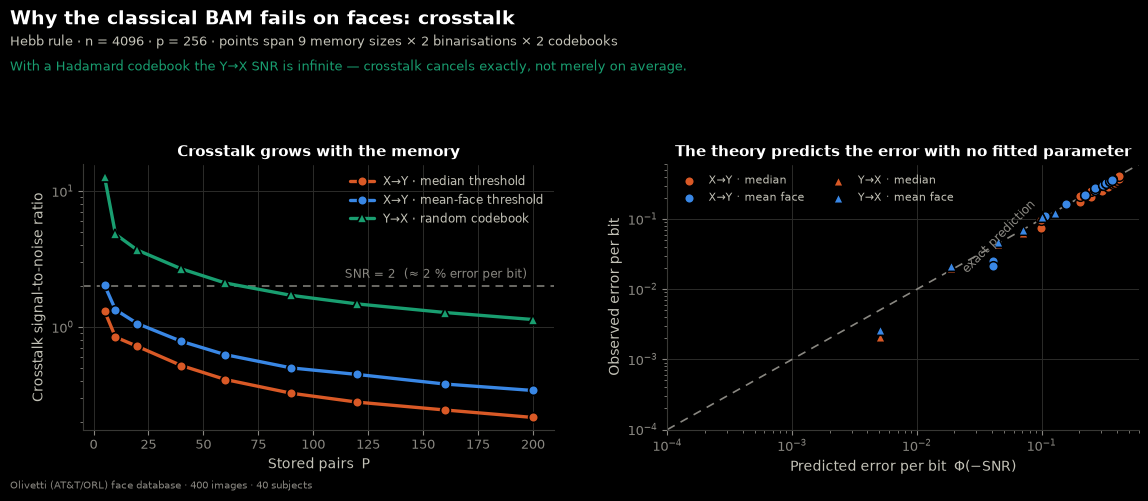

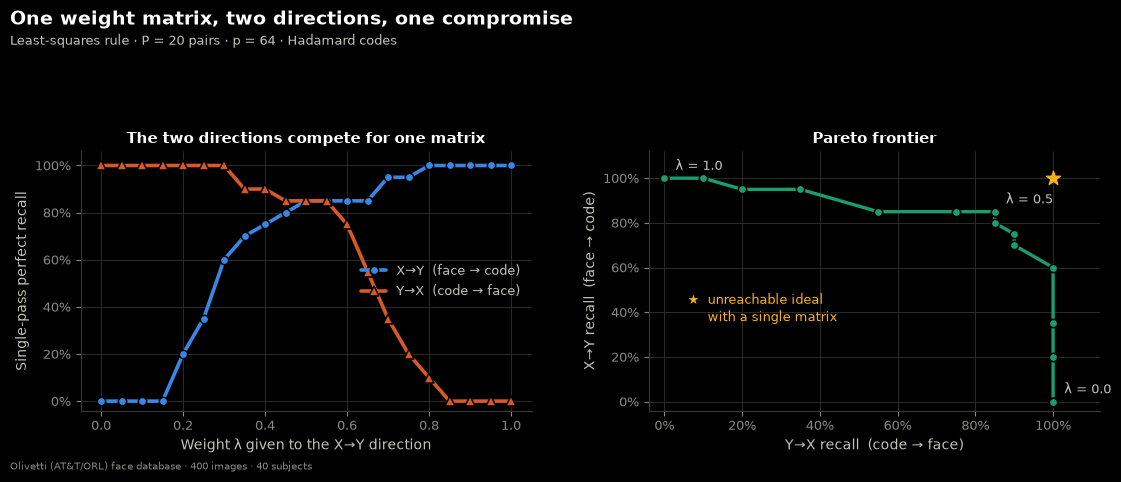

------------------------------------------------------------------------------
  written: results/tables/tab04_crosstalk.csv
  written: results/tables/tab04_tradeoff.csv
  written: results/figures/fig04_crosstalk.png
  written: results/figures/fig05_tradeoff.png
  total time: 4.1 s


In [34]:
def e4_main():
    t0 = header(
        4, "Crosstalk and the trade-off between directions",
        "Is the observed error predictable from the pattern correlations?",
    )

    df = e4_validate_theory()
    files = [save_table(df, "tab04_crosstalk.csv")]

    print("Mean correlation between stored faces (P = 200):")
    for method in E4_BINARIZATIONS:
        c = df[(df.binarization == method)
               & (df.P == 200)].iloc[0]["mean_correlation"]
        print(f"  {BINARIZATION_LABELS[method]:38s} {float(c):.3f}")

    print("\nMean codebook orthogonality (P = 200; 0 = perfectly orthogonal):")
    for cb in E4_CODEBOOKS:
        o = df[(df.codebook == cb) & (df.P == 200)].iloc[0]["code_orthogonality"]
        print(f"  {CODEBOOK_LABELS[cb]:38s} {float(o):.4f}")

    # Agreement between theory and measurement. Zero-error points are reported
    # separately: on a log scale they have no position, yet they are exactly
    # the cases where the prediction is exact (infinite SNR, Hadamard codes).
    exact = df[(df.predicted_error == 0) & (df.observed_error == 0)]
    positive = df[(df.predicted_error > 0) & (df.observed_error > 0)]
    conservative = df[(df.predicted_error > 0) & (df.observed_error == 0)]

    r_log = float(np.corrcoef(np.log10(positive.predicted_error),
                              np.log10(positive.observed_error))[0, 1])
    rho = float(spearmanr(df.predicted_error, df.observed_error).statistic)
    rel_err = float(np.median(
        np.abs(positive.observed_error - positive.predicted_error)
        / positive.predicted_error))

    print(f"\nAgreement between predicted and observed error ({len(df)} points):")
    print(f"  exact prediction of zero error ................... {len(exact)} points")
    print(f"  positive prediction, positive measurement ........ {len(positive)} points")
    print(f"      Pearson correlation in log-log ............... r = {r_log:.3f}")
    print(f"      median relative error of the prediction ...... {rel_err:.3f}")
    print(f"  positive prediction, zero measurement ............ "
          f"{len(conservative)} points")
    print(f"  Spearman correlation over all points ............. rho = {rho:.3f}")

    print("\nMean X→Y SNR (Hadamard codebook):")
    for method in E4_BINARIZATIONS:
        g = df[(df.binarization == method) & (df.direction == "X→Y")
               & (df.codebook == "hadamard")].sort_values("P")
        samples = " · ".join(f"P={int(r.P)}: {float(r.snr):.2f}"
                             for _, r in g.iterrows() if r.P in (5, 20, 90, 200))
        print(f"  {method:12s} {samples}")

    comp, _, _, _ = e4_sweep_tradeoff()
    files.append(save_table(comp, "tab04_tradeoff.csv"))
    best = comp.assign(total=comp.forward_pass + comp.backward_pass).sort_values(
        "total", ascending=False).iloc[0]
    print(f"\nBest compromise: λ = {float(best['lambda']):.2f} → "
          f"X→Y {float(best.forward_pass):.2f} · "
          f"Y→X {float(best.backward_pass):.2f}")

    files.append(e4_figure_crosstalk(df))
    files.append(e4_figure_tradeoff(comp))
    footer(t0, files)
    apply_theme()
    return df, comp


e4_df, e4_comp = e4_main()

---
# Parte 14 · Experimento 5 — Aplicação: quem é, e com que cara

## Pergunta

Os experimentos anteriores usam uma associação artificial um-para-um. Uma BAM
fica mais interessante quando a associação é **muitos-para-um**: várias
fotografias do mesmo indivíduo compartilham um único código de identidade. Isso
dá papéis semânticos distintos às duas direções:

* **X→Y** vira *identificação*: dada uma fotografia inédita, quem é esta pessoa?
* **Y→X** vira *evocação*: dado o nome, com que cara é esta pessoa?

E há um resultado exato, e bastante bonito, escondido aí. Com códigos de
Hadamard e a regra de Hebb, $W = \sum_k x_k y_k^{\mathsf T}$ e portanto

$$W y_c = \sum_k x_k\,(y_k^{\mathsf T} y_c) = p \sum_{k \in \text{classe } c} x_k,$$

de modo que $\operatorname{sgn}(W y_c)$ é **exatamente o voto majoritário
pixel a pixel das fotografias de treino daquele indivíduo**. A BAM hebbiana não
recupera uma fotografia armazenada: ela **sintetiza o protótipo da classe**. O
experimento verifica essa identidade numericamente.

## Protocolo

7 das 10 poses de cada indivíduo vão para treino (280 pares armazenados), 3
ficam de fora (120 fotografias nunca vistas). Como o código é um rótulo, a
saída X→Y é decodificada para a palavra-código mais próxima — é assim que um
sistema real a leria. Um classificador de vizinho mais próximo sobre os mesmos
vetores binarizados serve de linha de base honesta.

**Saídas:** `04_identification.gif`, `fig06_identification.png`,
`tab05_identification.csv`.

In [35]:
E5_CODE_LEN = 64  # 64 >= 40 + 1: the 40 non-degenerate Hadamard codes fit
E5_N_TRAIN = 7  # poses per subject used for training (the other 3 are held out)
E5_N_SEEDS = 6
E5_MAX_ITER = 20


def e5_decode(Yhat: np.ndarray, codes: np.ndarray) -> np.ndarray:
    """Index of the nearest (highest-correlation) codeword for each column.

    The raw Y-layer output is rarely a valid code; in a real system it goes
    through a decoder. With a Hadamard codebook this step is the
    maximum-likelihood decoding of an orthogonal code.
    """
    return np.argmax(codes.T @ Yhat, axis=0)


def e5_majority_vote(X: np.ndarray, target: np.ndarray) -> np.ndarray:
    """Class prototypes: pixel-wise majority vote."""
    classes = np.unique(target)
    out = np.empty((X.shape[0], len(classes)))
    for i, c in enumerate(classes):
        out[:, i] = np.sign(X[:, target == c].sum(axis=1))
    return out


def e5_evaluate(data, seed: int):
    """Fit the four rules and measure identification and evocation."""
    train, test = train_test_split(data.target, n_train=E5_N_TRAIN,
                                   seed=SEED + seed)
    X_tr, y_tr = data.X[:, train], data.target[train]
    X_te, y_te = data.X[:, test], data.target[test]

    classes = np.unique(data.target)
    codes = build_codebook("hadamard", len(classes), E5_CODE_LEN)
    Y_tr = codes[:, y_tr]  # the same code repeated for every pose
    prototypes = e5_majority_vote(X_tr, y_tr)

    rows, artifacts = [], {}
    for rule in RULES:
        model = BAM(rule, max_iter=E5_MAX_ITER, max_mt_epochs=30).fit(X_tr, Y_tr)

        pred_te = e5_decode(model.associate_forward(X_te), codes)
        pred_tr = e5_decode(model.associate_forward(X_tr), codes)
        evoked = model.associate_backward(codes)

        rows.append({
            "seed": seed,
            "rule": rule,
            "test_accuracy": float((pred_te == y_te).mean()),
            "train_accuracy": float((pred_tr == y_tr).mean()),
            "exact_code_test": perfect_recall_rate(
                model.associate_forward(X_te), codes[:, y_te]),
            "evocation_equals_prototype": perfect_recall_rate(evoked, prototypes),
            "evocation_matching_bits": float((evoked == prototypes).mean()),
        })
        artifacts[rule] = {"model": model, "evoked": evoked,
                           "predicted_test": pred_te}

    # Baseline: nearest neighbour by correlation, over the same vectors.
    nn = y_tr[np.argmax(X_tr.T @ X_te, axis=0)]
    rows.append({
        "seed": seed,
        "rule": "nearest_neighbour",
        "test_accuracy": float((nn == y_te).mean()),
        "train_accuracy": 1.0,
        "exact_code_test": float("nan"),
        "evocation_equals_prototype": float("nan"),
        "evocation_matching_bits": float("nan"),
    })

    artifacts["_data"] = {"X_te": X_te, "y_te": y_te, "codes": codes,
                          "prototypes": prototypes, "classes": classes}
    return pd.DataFrame(rows), artifacts


E5_ALL_LABELS = {**RULE_LABELS,
                 "nearest_neighbour": "Nearest neighbour (baseline)"}
E5_ALL_COLORS = {**RULE_COLOR, "nearest_neighbour": INK_MUTED}
E5_BAR_LABELS = {
    "hebb": "Hebb",
    "multiple_training": "Multiple training",
    "least_squares": "Least squares",
    "dense": "Dense (exponential)",
    "nearest_neighbour": "Nearest neighbour\n(baseline, no BAM)",
}

In [36]:
def e5_figure_identification(res: pd.DataFrame, artifacts: dict, side: int):
    """Accuracy bars on the left; evoked prototypes on the right."""
    apply_theme()
    d = artifacts["_data"]
    fig = plt.figure(figsize=(12.6, 5.6))
    gs = fig.add_gridspec(2, 5, width_ratios=[2.5, 0.30, 1, 1, 1],
                          left=0.145, right=0.965, top=0.695, bottom=0.135,
                          hspace=0.34, wspace=0.10)
    ax_b = fig.add_subplot(gs[:, 0])

    order = list(RULES) + ["nearest_neighbour"]
    means, errors, colors, labels = [], [], [], []
    for key in order:
        g = res[res.rule == key]["test_accuracy"].to_numpy()
        mean, ci = confidence_interval(g)
        means.append(mean)
        errors.append(ci)
        colors.append(E5_ALL_COLORS[key])
        labels.append(E5_BAR_LABELS[key])

    y = np.arange(len(order))
    ax_b.barh(y, means, height=0.62, color=colors, zorder=3)
    ax_b.errorbar(means, y, xerr=errors, fmt="none", ecolor=INK_SECONDARY,
                  elinewidth=1.4, capsize=4, zorder=4)
    for yi, m in zip(y, means, strict=True):
        ax_b.text(m + 0.018, yi, f"{100 * m:.1f}%", va="center", ha="left",
                  fontsize=9.5, color=INK_PRIMARY)
    ax_b.set_yticks(y, labels, fontsize=9.5)
    ax_b.invert_yaxis()
    ax_b.set_xlim(0, 1.12)
    ax_b.xaxis.set_major_formatter(pct_fmt(0))
    ax_b.set_xlabel("Identification accuracy on unseen photographs")
    ax_b.grid(axis="y", visible=False)
    chance = 1.0 / len(d["classes"])
    ax_b.axvline(chance, color=INK_MUTED, lw=1.1, ls=(0, (5, 4)), zorder=4)
    ax_b.annotate("chance (1/40)", xy=(chance, -0.62), xytext=(4, 0),
                  textcoords="offset points", fontsize=8.5, color=INK_MUTED,
                  va="center", annotation_clip=False)

    for col, c in enumerate((0, 1, 2)):
        ax_p = fig.add_subplot(gs[0, 2 + col])
        face_panel(ax_p, d["prototypes"][:, c], side,
                   "Class prototype" if col == 0 else "",
                   subtitle=f"subject {c + 1}")
        ax_e = fig.add_subplot(gs[1, 2 + col])
        evoked = artifacts["hebb"]["evoked"][:, c]
        same = bool((evoked == d["prototypes"][:, c]).all())
        face_panel(ax_e, evoked, side,
                   "Evoked by the Hebbian BAM" if col == 0 else "",
                   subtitle="identical" if same else "different",
                   border=GOOD if same else CRITICAL)

    figure_title(
        fig,
        "Telling who it is, and recalling what they look like",
        f"{E5_N_TRAIN} poses per subject stored (280 pairs) · 120 never-seen "
        f"test photographs · 40 identities · mean of {E5_N_SEEDS} seeds",
    )
    fig.text(0.012, 0.855,
             "Right: the class prototype (majority vote of the training poses) "
             "and what the Hebbian BAM evokes from the code. They are the same "
             "vector, bit for bit.",
             ha="left", va="top", fontsize=9, color=SERIES[2])
    credit(fig)
    target = FIGURES_DIR / "fig06_identification.png"
    fig.savefig(target, dpi=160)
    plt.show()
    return target


def e5_identification_gif(data, artifacts: dict, accuracy: float,
                          rule: str = "dense", n_examples: int = 10):
    """Square GIF: an unseen photograph goes in, a name and a face come out.

    The left panel is the input the network has never seen. The middle strip is
    the code it produces, marked against the correct identity's codeword. The
    right panel is what the *reverse* direction evokes from the answer — and
    that face is not any stored photograph, it is the class prototype.
    """
    d = artifacts["_data"]
    rng = np.random.default_rng(SEED)
    chosen = rng.choice(d["X_te"].shape[1], n_examples, replace=False)
    model = artifacts[rule]["model"]
    predictions = artifacts[rule]["predicted_test"]

    fig, top = new_square_figure("04_identification", n_train=E5_N_TRAIN)
    badge_y, top = top + 0.008, top - BADGE_GAP
    gs = fig.add_gridspec(
        3, 2, height_ratios=[1.0, 0.17, 0.34],
        left=0.055, right=0.965, top=top, bottom=PANEL_BOTTOM,
        hspace=0.34, wspace=0.10,
    )
    ax_photo = fig.add_subplot(gs[0, 0])
    ax_evoked = fig.add_subplot(gs[0, 1])
    ax_code = fig.add_subplot(gs[1, :])
    ax_txt = fig.add_subplot(gs[2, :])
    ax_txt.axis("off")

    movable: list = []
    hits = 0

    def update(i: int) -> None:
        nonlocal movable, hits
        for a in movable:
            a.remove()
        movable = []
        for ax in (ax_photo, ax_evoked, ax_code):
            ax.clear()
        if i == 0:
            hits = 0

        col = chosen[i]
        truth = int(d["y_te"][col])
        pred = int(predictions[col])
        right = pred == truth
        hits = sum(1 for k in chosen[: i + 1]
                   if int(predictions[k]) == int(d["y_te"][k]))

        for ax in (ax_photo, ax_evoked):
            ax.set_box_aspect(1.0)
        face_panel(ax_photo, d["X_te"][:, col], data.side,
                   PANEL_TEST_PHOTO,
                   subtitle=TRUE_SUBJECT.format(k=truth + 1),
                   border=INK_MUTED, title_size=PANEL_TITLE_SIZE,
                   subtitle_size=PANEL_SUBTITLE_SIZE)
        face_panel(ax_evoked, artifacts[rule]["evoked"][:, pred], data.side,
                   PANEL_PROTOTYPE,
                   subtitle=ANSWERED.format(k=pred + 1),
                   border=GOOD if right else CRITICAL,
                   title_size=PANEL_TITLE_SIZE,
                   subtitle_size=PANEL_SUBTITLE_SIZE)

        y_hat = model.associate_forward(d["X_te"][:, col : col + 1])[:, 0]
        code_panel(ax_code, y_hat, PANEL_NETWORK_CODE,
                   target=d["codes"][:, truth],
                   title_size=PANEL_TITLE_SIZE, marker_size=24)

        movable.append(ax_txt.text(
            0.0, 1.05, CORRECT if right else WRONG,
            transform=ax_txt.transAxes, va="top", ha="left",
            fontsize=BODY_SIZE + 3, color=GOOD if right else CRITICAL,
        ))
        movable.append(ax_txt.text(
            0.0, 0.55, ACCURACY_NOTE.format(
                value=format_percent(accuracy, 1, ptbr=True)),
            transform=ax_txt.transAxes, va="top", ha="left", fontsize=BODY_SIZE,
            color=INK_SECONDARY,
        ))
        movable.append(ax_txt.text(
            0.0, 0.10, RED_SQUARES_NOTE, transform=ax_txt.transAxes,
            va="top", ha="left", fontsize=BODY_SIZE - 3, color=INK_MUTED,
        ))
        movable.append(badge(fig, badge_y, PHOTO_COUNTER.format(
            k=i + 1, n=n_examples) + f"  ·  {hits}/{i + 1}"))
        if i == n_examples - 1:
            movable += takeaway(fig, "04_identification")

    return save_gif(fig, update, n_examples, "04_identification",
                    fps=2, hold_first=1, hold_last=12)


EXPERIMENT 5 — Application — face identification and prototype evocation
Question: Is the BAM good for anything once the association is many-to-one?
------------------------------------------------------------------------------
Protocol: 7 training poses and 3 test poses per subject · 40 identities · p = 64



  seed 1/6


  seed 2/6


  seed 3/6


  seed 4/6


  seed 5/6


  seed 6/6



Identification accuracy on unseen photographs:
  Hebb (Kosko, 1988)                 0.453 ± 0.023
  Multiple training                  0.453 ± 0.023
  Least squares                      0.868 ± 0.019
  Dense (exponential)                0.868 ± 0.015
  Nearest neighbour (baseline)       0.915 ± 0.015

Evocation: does the Y→X output match the class prototype?
  Hebb (Kosko, 1988)     classes identical to prototype: 1.00 · matching bits: 1.0000
  Multiple training      classes identical to prototype: 1.00 · matching bits: 1.0000
  Least squares          classes identical to prototype: 0.00 · matching bits: 0.8650
  Dense (exponential)    classes identical to prototype: 1.00 · matching bits: 1.0000


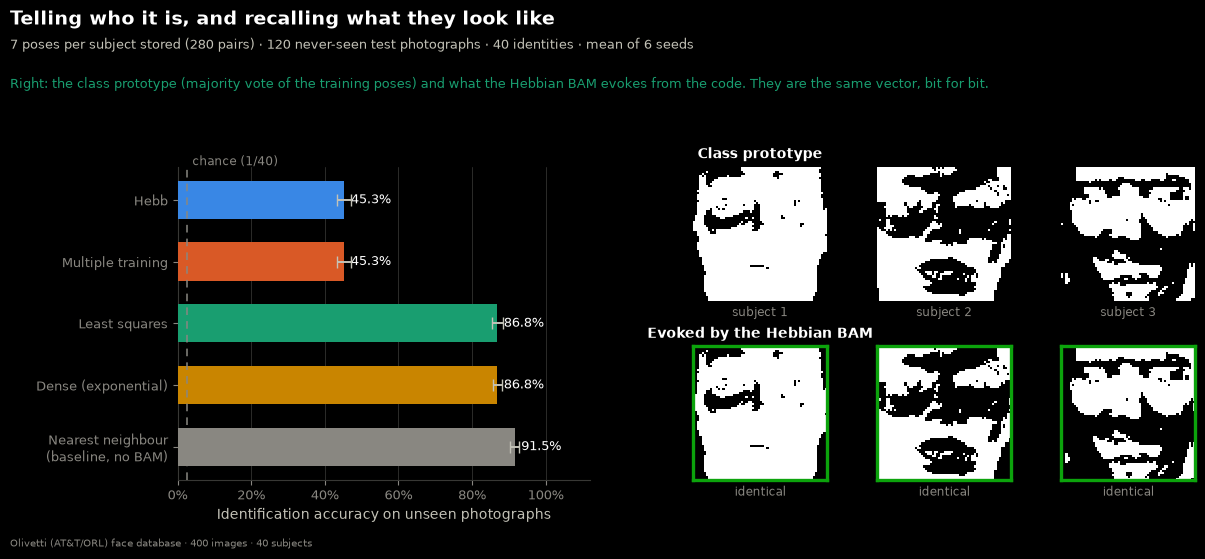

------------------------------------------------------------------------------
  written: results/tables/tab05_identification.csv
  written: results/figures/fig06_identification.png
  written: results/gifs/04_identification.gif
  total time: 15.7 s


In [37]:
def e5_main():
    t0 = header(
        5, "Application — face identification and prototype evocation",
        "Is the BAM good for anything once the association is many-to-one?",
    )
    data = load_dataset(method="mean-face")
    print(f"Protocol: {E5_N_TRAIN} training poses and {10 - E5_N_TRAIN} test "
          f"poses per subject · 40 identities · p = {E5_CODE_LEN}\n")

    parts, artifacts = [], None
    for seed in range(E5_N_SEEDS):
        df, art = e5_evaluate(data, seed)
        parts.append(df)
        if artifacts is None:
            artifacts = art
        print(f"  seed {seed + 1}/{E5_N_SEEDS}", flush=True)
    res = pd.concat(parts, ignore_index=True)
    files = [save_table(res, "tab05_identification.csv")]

    summary = (res.groupby("rule", sort=False).agg(["mean", "std"])["test_accuracy"]
               .reindex(list(RULES) + ["nearest_neighbour"]))
    print("\nIdentification accuracy on unseen photographs:")
    for key, row in summary.iterrows():
        print(f"  {E5_ALL_LABELS[key]:34s} {float(row['mean']):.3f} "
              f"± {float(row['std']):.3f}")

    print("\nEvocation: does the Y→X output match the class prototype?")
    for rule in RULES:
        g = res[res.rule == rule]
        print(f"  {RULE_LABELS[rule]:22s} classes identical to prototype: "
              f"{float(g.evocation_equals_prototype.mean()):.2f} · "
              f"matching bits: {float(g.evocation_matching_bits.mean()):.4f}")

    files.append(e5_figure_identification(res, artifacts, data.side))
    gif = e5_identification_gif(
        data, artifacts,
        accuracy=float(res[res.rule == "dense"].test_accuracy.mean()),
    )
    files.append(gif)
    footer(t0, files)
    apply_theme()
    return gif, res


e5_gif, e5_res = e5_main()

### Animação 4 — para que serve?

Fotografia inédita → identidade → o protótipo sintetizado daquela pessoa.

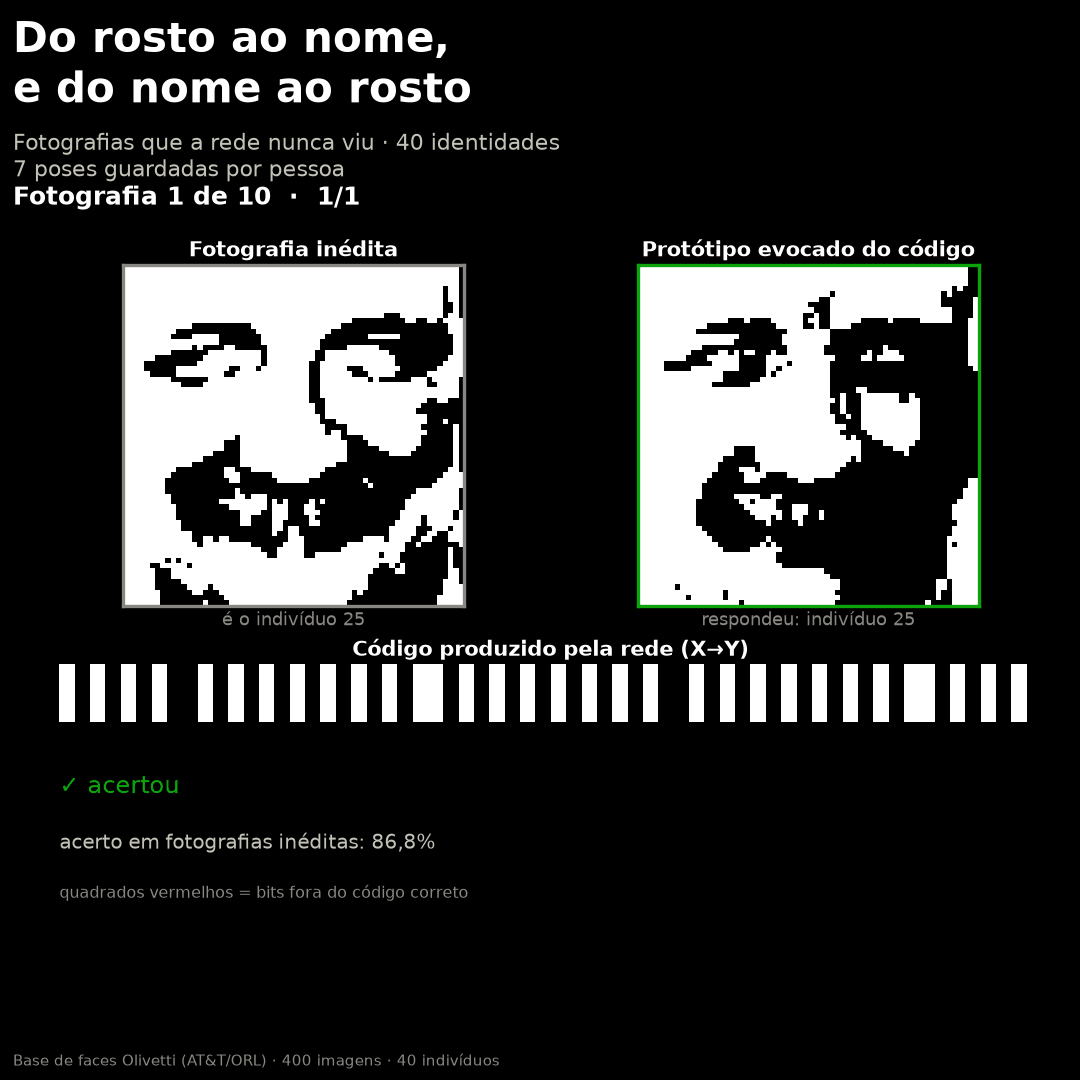

In [38]:
display(Image(str(e5_gif)))

---
# Parte 15 · Animação 5 — a rede sozinha: sinapses e disparos

Aqui não há gráfico nenhum. Só a rede.

## Toda a rede, sem amostragem

As outras animações mostram faces de 64×64, isto é, **4096 neurônios** na
camada X — impossível desenhar um a um. Para *ver* os neurônios, a rede
precisa ser pequena o bastante para caber inteira na tela. Esta é:

* camada X: **64 neurônios** (faces reduzidas a 8×8, desenhadas como grade);
* camada Y: **8 neurônios**;
* **512 sinapses — todas desenhadas individualmente.**

Não é um esquema ilustrativo: é uma BAM de verdade, treinada com dados
Olivetti de verdade. Verificamos antes de animar que, nessa escala, ela ainda
funciona — os 4 pares são pontos fixos e a recuperação é exata mesmo com 30 %
dos neurônios de X invertidos.

## Ato 1 — o aprendizado

A rede começa **sem sinapse alguma** ($W = 0$). Os pares são apresentados um a
um e cada apresentação soma o seu produto externo aos pesos:

$$W \leftarrow W + x_k\,y_k^{\mathsf T}.$$

É todo o aprendizado hebbiano da BAM — e dá para vê-lo acontecer: as sinapses
nascem e engrossam a cada par. Azul é peso positivo, vermelho é negativo, e a
espessura é $|w_{ij}|$.

## Ato 2 — o disparo

Uma sonda corrompida é carregada na camada X e a rede é solta. Cada meia-etapa
tem dois quadros:

1. **o sinal viajando** — acendem só as sinapses que de fato carregam sinal,
   com cor pelo sinal da contribuição $w_{ij}\,x_i$ e intensidade pelo módulo
   dela. É literalmente o campo local sendo somado.
2. **os neurônios acionando** — a camada de destino salta para o sinal do
   campo que recebeu.

Anel vermelho marca todo neurônio de X que ainda difere do padrão armazenado.
Eles somem quando a rede converge.

In [39]:
A5_SIDE = 8  # X layer drawn as an 8x8 grid -> 64 neurons
A5_CODE_LEN = 8  # Y layer -> 8 neurons
A5_P = 4  # stored pairs
A5_NOISE = 0.20  # fraction of X neurons corrupted in the probe

A5_N_X = A5_SIDE * A5_SIDE
A5_N_SYNAPSES = A5_N_X * A5_CODE_LEN

# --- geometry ---------------------------------------------------------------
# The panel is wider than it is tall, so the axes are given *isotropic* units:
# `ylim` spans `H = height/width` while `xlim` spans 1. One axes unit is then
# the same number of pixels in both directions, which is what keeps the 8x8
# grid square instead of stretched.
A5_PANEL_LEFT, A5_PANEL_RIGHT = 0.05, 0.965
A5_GRID_SPACING = 0.060  # centre-to-centre distance between X neurons
A5_GRID_X0 = 0.045  # left edge of the grid
A5_Y_COL = 0.95  # x position of the Y column


def a5_grid_positions(height: float) -> np.ndarray:
    """(64, 2) positions of the X neurons, row-major like the image."""
    span = A5_GRID_SPACING * (A5_SIDE - 1)
    y_top = (height + span) / 2.0
    xs = A5_GRID_X0 + A5_GRID_SPACING * np.arange(A5_SIDE)
    ys = y_top - A5_GRID_SPACING * np.arange(A5_SIDE)
    return np.array([(xs[c], ys[r]) for r in range(A5_SIDE) for c in range(A5_SIDE)])


def a5_column_positions(height: float) -> np.ndarray:
    """(8, 2) positions of the Y neurons, spanning the same vertical band."""
    span = A5_GRID_SPACING * (A5_SIDE - 1)
    y_top = (height + span) / 2.0
    ys = y_top - span * np.arange(A5_CODE_LEN) / (A5_CODE_LEN - 1)
    return np.array([(A5_Y_COL, y) for y in ys])


def a5_neuron_face(state: float) -> str:
    """Fill colour of a neuron: lit for +1, dark for -1, grey for 0."""
    if state > 0:
        return INK_PRIMARY
    if state < 0:
        return "#161616"
    return "#3a3a3a"

In [40]:
def a5_build_frames(X: np.ndarray, Y: np.ndarray, model: BAM, probe: np.ndarray):
    """The full storyboard: one dict per rendered frame."""
    frames = []

    # --- Act 1: the synapses are built, one stored pair at a time.
    W = np.zeros((A5_N_X, A5_CODE_LEN))
    frames.append({
        "act": 1, "W": W.copy(), "x": np.zeros(A5_N_X),
        "y": np.zeros(A5_CODE_LEN),
        "caption": "a rede começa sem nenhuma sinapse", "flow": None,
        "wrong": None,
    })
    for k in range(A5_P):
        # The pair is presented: both layers are clamped to it.
        frames.append({
            "act": 1, "W": W.copy(), "x": X[:, k], "y": Y[:, k],
            "caption": f"mostramos o par {k + 1} para a rede", "flow": None,
            "wrong": None,
        })
        W = W + np.outer(X[:, k], Y[:, k])
        frames.append({
            "act": 1, "W": W.copy(), "x": X[:, k], "y": Y[:, k],
            "caption": "W ← W + x yᵀ   ·   as sinapses ficam mais fortes",
            "flow": None,
            "wrong": None,
        })

    # --- Act 2: a corrupted probe is loaded and the network is left to run.
    traj = model.recall(x0=probe)
    W_final = model.W
    frames.append({
        "act": 2, "W": W_final, "x": traj.xs[0], "y": traj.ys[0],
        "caption": f"entra uma sonda com {int(A5_NOISE * 100)}% dos neurônios "
                   f"de X invertidos",
        "flow": None, "wrong": traj.xs[0] != X[:, 0],
    })

    for t in range(1, len(traj.xs)):
        step = traj.steps[t]
        x_prev, y_prev = traj.xs[t - 1], traj.ys[t - 1]
        x_now, y_now = traj.xs[t], traj.ys[t]

        # (a) the signal travelling: per-synapse contribution to the field.
        if step == "X->Y":
            flow = ("forward", W_final * x_prev[:, None])
            caption = "os neurônios de X disparam em Y"
        else:
            flow = ("backward", W_final * y_prev[None, :])
            caption = "os neurônios de Y disparam de volta em X"
        frames.append({
            "act": 2, "W": W_final, "x": x_prev, "y": y_prev,
            "caption": caption, "flow": flow, "wrong": x_prev != X[:, 0],
        })

        # (b) the destination layer settles on the sign of the field it got.
        last = t == len(traj.xs) - 1
        settled = "o par ficou estável" if last else (
            "a camada Y se atualiza" if step == "X->Y"
            else "a camada X se atualiza")
        frames.append({
            "act": 2, "W": W_final, "x": x_now, "y": y_now,
            "caption": settled, "flow": None, "wrong": x_now != X[:, 0],
        })

    return frames, traj

In [41]:
def a5_neurons_gif():
    """Square GIF: the whole network, learning and then firing."""
    data = load_dataset(method="mean-face", side=A5_SIDE)
    idx = one_index_per_subject(data.target)[:A5_P]
    X = data.X[:, idx]
    Y = build_codebook("hadamard", A5_P, A5_CODE_LEN)
    model = BAM("hebb", max_iter=12).fit(X, Y)

    rng = np.random.default_rng(SEED)
    probe = bit_flip_noise(X[:, 0:1], A5_NOISE, rng)[:, 0]

    frames, traj = a5_build_frames(X, Y, model, probe)
    print(f"n = {A5_N_X} · p = {A5_CODE_LEN} · P = {A5_P} · "
          f"{A5_N_SYNAPSES} synapses")
    print(f"  stored pairs that are fixed points: "
          f"{int(model.stable_pairs().sum())}/{A5_P}")
    print(f"  probe: {int((probe != X[:, 0]).sum())} of {A5_N_X} X neurons wrong")
    print(f"  recall: {traj.n_iter} iterations · exact = "
          f"{np.array_equal(traj.x_final, X[:, 0])}")
    print(f"  {len(frames)} frames")

    w_max = float(np.abs(model.W).max())

    fig, top = new_square_figure("06_neurons")
    badge_y = top - 0.030
    top = badge_y - 0.040

    width = A5_PANEL_RIGHT - A5_PANEL_LEFT
    ax = fig.add_axes((A5_PANEL_LEFT, PANEL_BOTTOM, width, top - PANEL_BOTTOM))
    height = (top - PANEL_BOTTOM) / width  # isotropic axes units
    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(0.0, height)
    ax.axis("off")

    pos_x = a5_grid_positions(height)
    pos_y = a5_column_positions(height)

    # Marker areas in points², matched to the neuron spacing so that the
    # circles never touch: 1 pt = dpi/72 px at this figure's resolution.
    pt_per_unit = width * 1080.0 * 72.0 / 100.0
    size_x = (0.58 * A5_GRID_SPACING * pt_per_unit) ** 2 * np.pi / 4.0
    size_y = (0.78 * A5_GRID_SPACING * pt_per_unit) ** 2 * np.pi / 4.0

    # Static layer captions, just above the neurons they name.
    cap_y = pos_x[:, 1].max() + 0.055
    ax.text(A5_GRID_X0 + A5_GRID_SPACING * (A5_SIDE - 1) / 2, cap_y,
            f"camada X · {A5_N_X} neurônios", ha="center", va="bottom",
            fontsize=BODY_SIZE - 1, color=INK_SECONDARY)
    ax.text(A5_Y_COL, cap_y, f"camada Y · {A5_CODE_LEN}", ha="center",
            va="bottom", fontsize=BODY_SIZE - 1, color=INK_SECONDARY)

    movable: list = []

    def update(i: int) -> None:
        nonlocal movable
        for a in movable:
            a.remove()
        movable = []
        f = frames[i]
        W, flow = f["W"], f["flow"]

        # --- synapses ------------------------------------------------------
        if flow is None:
            # Resting state: every synapse drawn at its own weight.
            scale = w_max or 1.0
            for a in range(A5_N_X):
                for b in range(A5_CODE_LEN):
                    w = W[a, b] / scale
                    if abs(w) < 1e-9:
                        continue
                    movable.append(ax.plot(
                        [pos_x[a, 0], pos_y[b, 0]], [pos_x[a, 1], pos_y[b, 1]],
                        color=SERIES[0] if w > 0 else CRITICAL,
                        lw=0.35 + 1.5 * abs(w), alpha=0.05 + 0.22 * abs(w),
                        solid_capstyle="round", zorder=2)[0])
        else:
            # Firing: only the synapses actually carrying signal, at the
            # strength of the contribution they make to the field.
            _, contrib = flow
            scale = float(np.abs(contrib).max()) or 1.0
            for a in range(A5_N_X):
                for b in range(A5_CODE_LEN):
                    c = contrib[a, b] / scale
                    if abs(c) < 0.18:
                        continue
                    movable.append(ax.plot(
                        [pos_x[a, 0], pos_y[b, 0]], [pos_x[a, 1], pos_y[b, 1]],
                        color=SERIES[0] if c > 0 else CRITICAL,
                        lw=0.4 + 2.4 * abs(c), alpha=0.10 + 0.55 * abs(c),
                        solid_capstyle="round", zorder=2)[0])

        # --- neurons -------------------------------------------------------
        wrong = f["wrong"]
        bad = np.zeros(A5_N_X, dtype=bool) if wrong is None else np.asarray(wrong)
        movable.append(ax.scatter(
            pos_x[:, 0], pos_x[:, 1], s=size_x,
            color=[a5_neuron_face(v) for v in f["x"]],
            edgecolors=[CRITICAL if b else "#5a5a58" for b in bad],
            linewidths=[2.6 if b else 1.1 for b in bad], zorder=5))
        movable.append(ax.scatter(
            pos_y[:, 0], pos_y[:, 1], s=size_y,
            color=[a5_neuron_face(v) for v in f["y"]],
            edgecolors="#8a8a86", linewidths=1.8, zorder=5))

        act = "aprendizado" if f["act"] == 1 else "disparo"
        movable.append(badge(fig, badge_y, f"{act}  ·  {f['caption']}"))
        if i == len(frames) - 1:
            movable += takeaway(fig, "06_neurons")

    return save_gif(fig, update, len(frames), "06_neurons", fps=2,
                    hold_first=2, hold_last=14)


a5_gif = a5_neurons_gif()
apply_theme()
print("written:", a5_gif.relative_to(ROOT))

n = 64 · p = 8 · P = 4 · 512 synapses
  stored pairs that are fixed points: 4/4
  probe: 14 of 64 X neurons wrong
  recall: 2 iterations · exact = True
  18 frames


written: results/gifs/06_neurons.gif


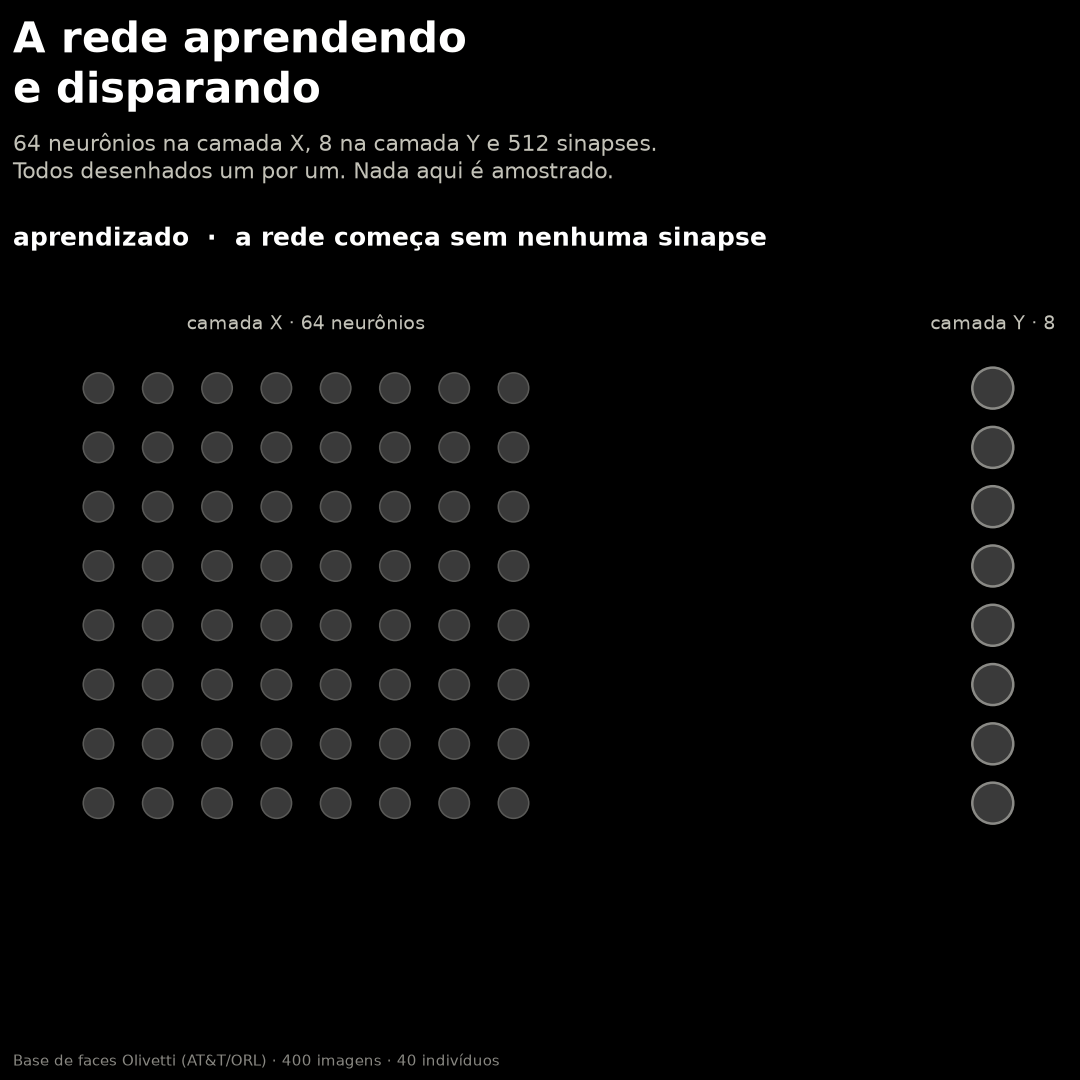

In [42]:
display(Image(str(a5_gif)))

---
# Parte 16 · Conclusões

1. **Estabilidade incondicional é uma garantia fraca.** A BAM sempre converge,
   inclusive quando converge para lixo. Verificado ao longo de 800 trajetórias
   sem uma única violação da monotonicidade da energia — e com estados
   espúrios em quase toda configuração da regra clássica com $P \geq 20$.

2. **A capacidade real em dados correlacionados fica uma ordem de grandeza
   abaixo das previsões clássicas.** Kosko prevê 256 pares; a análise i.i.d.
   prevê 23; medimos **capacidade útil zero** no sentido face→código. A
   diferença não é ruído experimental, é a correlação entre as faces
   (0,19–0,32), ausente de ambas as previsões.

3. **O erro é previsível.** O modelo de *crosstalk* reproduz o erro por bit sem
   nenhum parâmetro ajustado ($r = 0{,}984$ em log-log, erro relativo mediano
   de 4 %). Quem projeta uma BAM pode dimensioná-la antes de treiná-la,
   calculando $\Phi(-n/\sqrt{\sum c^2})$ a partir da matriz de Gram dos padrões.

4. **A camada de rótulos é a variável de projeto barata.** Trocar códigos
   aleatórios por códigos de Hadamard multiplica por 20 a capacidade
   código→face, sem custo. É a melhor intervenção custo-benefício de todo o
   estudo.

5. **Mas a bidirecionalidade cobra o preço da pior direção.** Nenhum ganho
   unidirecional sobrevive à ressonância se a outra direção for ruim. Em
   aplicações reais isso significa que uma BAM só deve ressoar quando as duas
   direções são confiáveis; caso contrário, use-a como um par de mapas de
   passagem única — que é, de fato, como ela funciona bem.

6. **A interação exponencial conserta tudo o que a regra clássica não
   conserta** — capacidade, robustez e ressonância — mas ao custo de abandonar
   a matriz de pesos, e com ela a implementação local que era a motivação
   biológica original do modelo. O ganho é real e o preço conceitual também.

## Limitações

* **Um único conjunto de dados.** Todos os números aqui se referem à
  Olivetti/ORL, com faces alinhadas, fundo controlado e apenas 40 indivíduos.
  As conclusões qualitativas (o *crosstalk* governa a capacidade; a
  ortogonalidade ajuda uma direção; a ressonância propaga o erro da pior
  direção) dependem apenas da correlação entre padrões e devem transferir; os
  valores numéricos, não.
* **A binarização é obrigatória.** A BAM é bipolar por construção. Binarizar
  descarta a informação de intensidade que um classificador real usaria —
  parte da diferença para o vizinho mais próximo pode vir daí.
* **O *multiple training* foi limitado a 25–30 épocas** nas varreduras, por
  custo. Ele não converge em faces dentro desse orçamento; não podemos
  descartar que convergiria com um orçamento muito maior, embora $q_k$ cresça
  sem sinal de assentar.
* **A regra densa usou $\beta = 12$ fixo**, sem ajuste por configuração. Um
  $\beta$ ajustado provavelmente melhoraria seus resultados, não os pioraria.
* **O modelo de *crosstalk* supõe independência entre os bits da camada de
  destino** ao converter erro por bit em recuperação perfeita. Os erros são
  correlacionados através das mesmas memórias interferentes, de modo que a
  curva de recuperação perfeita prevista funciona como um limite superior
  otimista — razão pela qual a validação na Parte 13 é feita sobre o erro
  **por bit**, que não depende dessa suposição.

## Referências

- Kosko, B. (1988). Bidirectional associative memories. *IEEE Transactions on
  Systems, Man, and Cybernetics*, 18(1), 49–60.
- Haines, K. & Hecht-Nielsen, R. (1988). A BAM with increased information
  storage capacity. *IEEE International Conference on Neural Networks*.
- Wang, Y.-F., Cruz, J. B. & Mulligan, J. H. (1990). Two coding strategies for
  bidirectional associative memory. *IEEE Transactions on Neural Networks*,
  1(1), 81–92.
- McEliece, R. J., Posner, E. C., Rodemich, E. R. & Venkatesh, S. S. (1987).
  The capacity of the Hopfield associative memory. *IEEE Transactions on
  Information Theory*, 33(4), 461–482.
- Krotov, D. & Hopfield, J. J. (2016). Dense associative memory for pattern
  recognition. *Advances in Neural Information Processing Systems*, 29.
- Ramsauer, H. et al. (2020). Hopfield networks is all you need.
  *arXiv:2008.02217*.